# SynCOM tests: periodic blobs (v3-periodic_blobs)

This notebook checks the changes from **v2-fixed** to **v3-periodic_blobs**, and shows the new behaviour with plots. Each section has:
- **Change**: what was changed and why.
- **Physics**: what the model should do physically.
- **Expected**: what the test checks.
- **Observed**: what the run actually showed.

Each section ends in an `assert`, so running the whole notebook without errors means every check passed.

### The two problems in v2-fixed
1. **Blobs ran out before the end of the simulation.** Each blob was a fixed train of 7 copies at $r + n(Pv + L)$, $n = 0, \pm2, \pm4, \pm6$, carried outward rigidly. No new copy was ever released, so after a few hours of simulated time most position angles were dark.
2. **Wrong launch radius.** `radial_i = 5 R☉ / Δr = 352 px` counted the 5 R☉ offset twice, because pixel 0 of the polar image is already 5 R☉. Blobs started at about 9.9 R☉.

### The v3 model
Every blob is a source that launches a blob **each time its period is up**: at $\tau = \ldots, -P, 0, P, 2P, \ldots$ on the blob's own clock $\tau = t + t_0$. The source was already launching before the first frame and keeps launching until the last. **A blob begins from its centre:** at the moment of launch its centre is at $r_0 = -12L$ px, six radial widths ($6 \times 2L$) below 5 R☉, behind the occulter. It slides into the field fully formed. Launch number $k$ (its centre) is at

$$r_k(\tau) = r_0 + v\,(\tau - kP),\qquad k_\text{lo} \le k \le k_\text{hi} = \lfloor \tau / P \rfloor ,$$

where $k_\text{lo}$ is the oldest launch still inside the image. It is negative when launches from before the first frame are still in the field. One blob's launches are $\lambda = vP$ apart along the radius. At a fixed radius, the brightness repeats every $P$.

| section | test |
|---|---|
| 1 | `gaussian_profile`: shape and wrap-around at 0°/360° |
| 2 | v2 against v3: the field stays full, from the first frame |
| 3 | launch behind the occulter: equal brightness at every radius |
| 4 | one blob, $P$ = 1 h: it reappears every period |
| 5 | periodicity in the cube (radius–time diagrams) |
| 6 | frequencies in the images against `syncom_load` (Fourier power spectrum); the period range measured blind |
| 7 | the 30-frame FITS sample |
| 8 | storage (for reference; no compression is applied) |
| 9 | planets in the frames (v4-planet_body) |
| 10 | summary |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from punchbowl.data.visualize import cmap_punch

from syncom_prams import default_syncom_prams, POLAR_PHI_RANGE, POLAR_RHO_RANGE
from syncom_load import syncom_load, syncom_blob_table
from gaussian_function import gaussian_profile
from syncom_image import syncom_image, angular_profiles, launch_range
from syncom_fits import load_fits_cube
from syncom_path import syncom_run_name, syncom_run_dir
from polar_to_rect import polar_to_rect
from syncom_movie import plot_rect_image

# Reference run of these tests: 2000 blobs, scale factor 2 (section 6c analyses the main notebook's 10000-blob run)
N_BLOBS, SCALE = 2000, 2.0
params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, SYNCOM_SCALE_FACTOR=SCALE)
load_struc = syncom_load(params, simple=True)
blobs = syncom_blob_table(params, load_struc, SCALE)

NX, NY = params["syncom_nx"], params["syncom_ny"]
DR = params["syncom_pixel"]                 # [Rsun/px]
CADENCE = params["syncom_cadence"]          # [s/frame]
FRAMES = np.arange(300)                     # time steps of the main run

def to_rsun(pixel):
    """Radial pixel -> distance from the Sun centre [Rsun] (pixel 0 = POLAR_RHO_RANGE[0])."""
    return POLAR_RHO_RANGE[0] + np.asarray(pixel) * DR

assert np.isclose(to_rsun(NY - 1), POLAR_RHO_RANGE[1])     # plots and simulation use the same radial range

print(f"{N_BLOBS} blobs: v = {blobs['v'].min():.2f}-{blobs['v'].max():.2f} px/frame, "
      f"P = {blobs['period'].min():.1f}-{blobs['period'].max():.1f} frames, L = {blobs['L'].min():.1f}-{blobs['L'].max():.1f} px")

No file or date entered. Using default: syncom_20140414_densfix.sav
2000 blobs: v = 4.56-10.63 px/frame, P = 18.0-36.0 frames, L = 2.0-22.0 px


## 1. `gaussian_profile`: shape and wrap-around

**Change.** `gaussian_profile(npixel, avr, st_dev, periodic=False)` replaced the inline Gaussians and the `np.roll` shifts of earlier versions. It's vectorised: give arrays of centres and widths and it returns one profile per blob.

**Physics.** A blob is a smooth, localised density enhancement. The white-light brightness is linear in density (Thomson scattering in an optically thin corona), so each blob is a Gaussian and blobs simply add. Position angle lives on a circle, so a blob at 359.9° must continue at 0°. Radius is an open boundary, so it must **not** wrap.

**Expected.**
- Peak 1 at the centre, and $e^{-1/2} = 0.6065$ at one width from it.
- With `periodic=True`, a blob centred at pixel 3599 (359.9°) is symmetric across the 0°/360° seam.
- With `periodic=False`, it is simply cut at the edge.


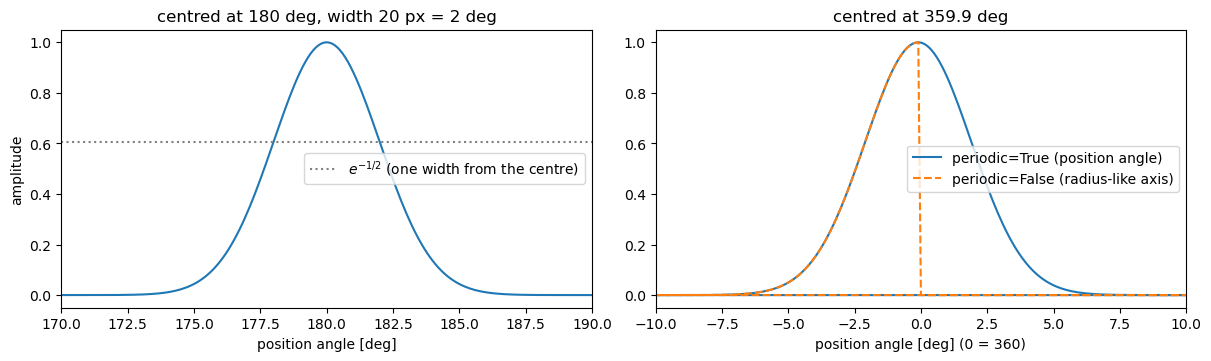

gaussian_profile: shape and wrap-around OK


In [2]:
x = np.arange(3600)
sigma = 20.0

centred = gaussian_profile(3600, 1800, sigma)                        # blob in the middle
at_edge_periodic = gaussian_profile(3600, 3599, sigma, periodic=True)  # blob at 359.9 deg, wraps
at_edge_open = gaussian_profile(3600, 3599, sigma, periodic=False)   # same blob, no wrap

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
ax[0].plot(x * 0.1, centred)
ax[0].axhline(np.exp(-0.5), ls=":", c="gray", label=r"$e^{-1/2}$ (one width from the centre)")
ax[0].set(xlim=(170, 190), xlabel="position angle [deg]", ylabel="amplitude", title="centred at 180 deg, width 20 px = 2 deg")
ax[0].legend()

shifted = np.roll(np.arange(3600), 100)                              # show 350 deg ... 10 deg in one piece
pa = (shifted * 0.1 + 180) % 360 - 180
ax[1].plot(pa, at_edge_periodic[shifted], label="periodic=True (position angle)")
ax[1].plot(pa, at_edge_open[shifted], "--", label="periodic=False (radius-like axis)")
ax[1].set(xlim=(-10, 10), xlabel="position angle [deg] (0 = 360)", title="centred at 359.9 deg")
ax[1].legend()
plt.show()

assert np.isclose(centred.max(), 1.0) and np.isclose(centred[1800 + 20], np.exp(-0.5))
d = np.arange(1, 60)
assert np.allclose(at_edge_periodic[3599 - d], at_edge_periodic[(3599 + d) % 3600])  # symmetric across 0/360
assert at_edge_open[:60].max() < 1e-30                                              # open axis: nothing wraps
print("gaussian_profile: shape and wrap-around OK")

**Observed.** The peak is 1.000 at the centre and 0.6065 at one width, as expected. The blob centred at 359.9° is symmetric across the 0°/360° seam: values at 359.9° − d and 359.9° + d agree to round-off. The non-periodic profile is exactly zero on the other side of the edge. ✅

## 2. v2 against v3: the field stays full, from the first frame

**Change.** In v2, each blob was a rigid train of 7 copies that was never renewed. In v3, each blob is launched again every period, and it was already launching before the first frame.

**Physics.** A periodic source in a steady wind fills the whole field with a train of blobs $\lambda = vP$ apart. Once a source has run for longer than the time a launch needs to reach the top of the field, $(12L + N_r)/v \approx 200$ frames at most, the number of its launches inside the field stops changing. This is a **statistical steady state**. Every v3 source has been launching since long before frame 0 ($k < 0$), so the steady state holds from the first frame.

**Expected.**
- v2: the number of copies inside the field falls to almost zero by frame 299 (3425 → 1804 → 303 → 3 at frames 0, 100, 200, 299).
- v3: the number of launches inside the field is the same, within 5%, at **every** frame from 0 to 299. There is no spin-up.
- Both are counted the same way: centres within $4L$ of the field.


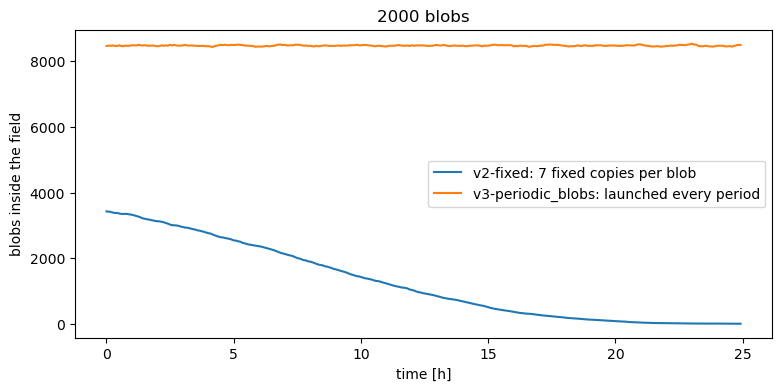

frame   0:  v2  3425   v3  8465
frame 100:  v2  1804   v3  8456
frame 150:  v2   926   v3  8479
frame 200:  v2   303   v3  8447
frame 299:  v2     3   v3  8496
v3, all 300 frames: 8435-8534 (spread 1.2%)


In [3]:
def visible_v2(t):
    """Number of v2 copies whose centre is inside the field at time step t (v2-fixed model)."""
    r_start_v2 = load_struc["outarray"][:, 0] / DR                     # v2 launch radius: 352 px (~9.9 Rsun)
    r = r_start_v2 + (t + blobs["time_0"]) * blobs["v"]               # rigid train moves outward forever
    count = 0
    for n in (0, 2, 4, 6, -2, -4, -6):                                # the 7 fixed copies
        c = r + n * blobs["period"] * blobs["v"] + n * blobs["L"]
        count += np.sum((c > -4 * blobs["L"]) & (c < NY + 4 * blobs["L"]))
    return int(count)


def visible_v3(t):
    """Number of v3 launches whose centre is inside the field at time step t (k_lo <= k <= k_hi)."""
    tau, k_lo, k_hi = launch_range(blobs, t, NY)
    count = 0
    for k in range(int(k_lo.min()), int(k_hi.max()) + 1):            # k < 0: launched before the first frame
        c = blobs["r0"] + blobs["v"] * (tau - k * blobs["period"])
        count += np.sum((k >= k_lo) & (k <= k_hi) & (c > -4 * blobs["L"]) & (c < NY + 4 * blobs["L"]))
    return int(count)


n_v2 = np.array([visible_v2(t) for t in FRAMES])
n_v3 = np.array([visible_v3(t) for t in FRAMES])

plt.figure(figsize=(9, 4))
plt.plot(FRAMES * CADENCE / 3600, n_v2, label="v2-fixed: 7 fixed copies per blob")
plt.plot(FRAMES * CADENCE / 3600, n_v3, label="v3-periodic_blobs: launched every period")
plt.xlabel("time [h]"); plt.ylabel("blobs inside the field"); plt.legend(); plt.title(f"{N_BLOBS} blobs")
plt.show()

for t in (0, 100, 150, 200, 299):
    print(f"frame {t:3d}:  v2 {n_v2[t]:5d}   v3 {n_v3[t]:5d}")

print(f"v3, all 300 frames: {n_v3.min()}-{n_v3.max()} (spread {100 * (n_v3.max() - n_v3.min()) / n_v3.mean():.1f}%)")
assert n_v2[299] < 0.01 * n_v3[299]                        # v2 has run out, v3 has not
assert n_v3.min() > 0.95 * n_v3.max()                       # v3 is in steady state from frame 0 (no spin-up)

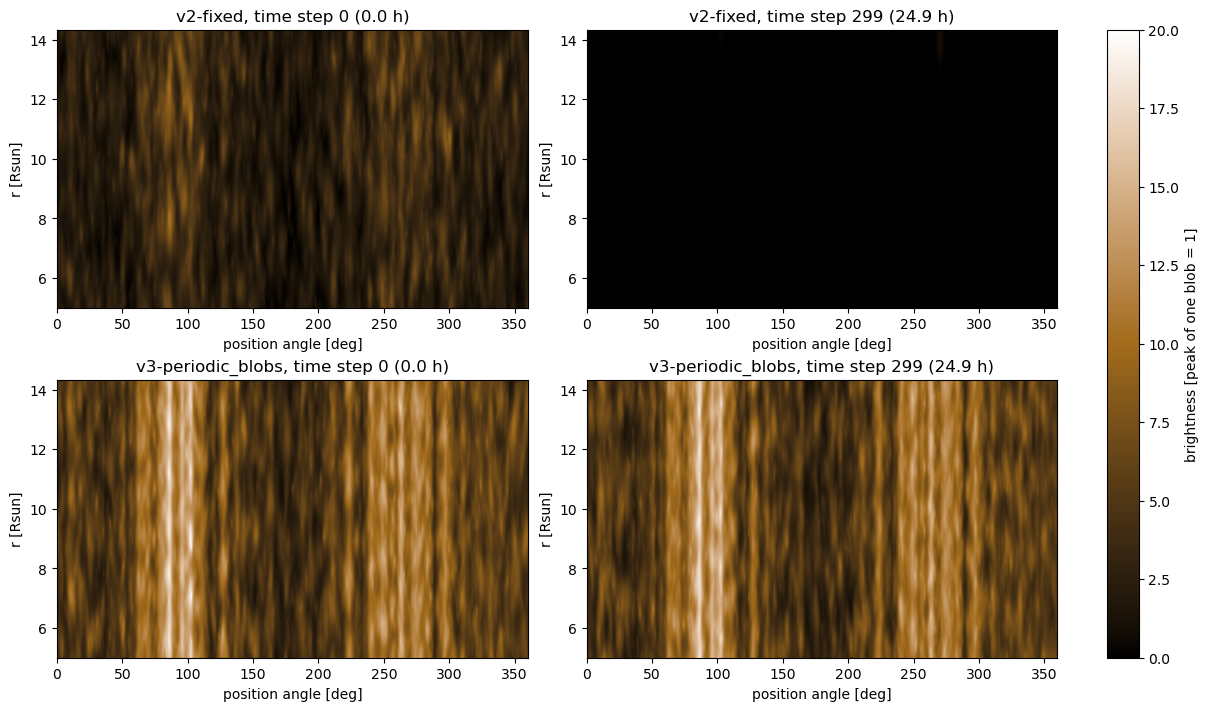

In [4]:
def frame_v2(t):
    """v2-fixed image at time step t (same formula as syncom_image in v2-fixed), for comparison."""
    r = load_struc["outarray"][:, 0] / DR + (t + blobs["time_0"]) * blobs["v"]
    gy = sum(gaussian_profile(NY, r + n * blobs["period"] * blobs["v"] + n * blobs["L"], 2 * blobs["L"])
             for n in (0, 2, 4, 6, -2, -4, -6))
    return angular_profiles(params, blobs).T @ gy

gx = angular_profiles(params, blobs)
fig, ax = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for col, t in enumerate((0, 299)):
    for row, (name, img) in enumerate((("v2-fixed", frame_v2(t)), ("v3-periodic_blobs", syncom_image(params, blobs, t, gx=gx)))):
        im = ax[row, col].imshow(img.T, origin="lower", aspect="auto", cmap=cmap_punch, vmin=0, vmax=20,
                                 extent=[0, 360, *to_rsun([0, NY - 1])])
        ax[row, col].set(title=f"{name}, time step {t} ({t * CADENCE / 3600:.1f} h)", xlabel="position angle [deg]", ylabel="r [Rsun]")
fig.colorbar(im, ax=ax, label="brightness [peak of one blob = 1]")
plt.show()

**Observed.** | frame (time) | 0 (0 h) | 100 (8.3 h) | 150 (12.5 h) | 200 (16.7 h) | 299 (24.9 h) |
|---|---|---|---|---|---|
| v2-fixed copies in the field | 3425 | 1804 | 926 | 303 | **3** |
| v3-periodic_blobs launches in the field | **8465** | 8456 | 8479 | 8447 | **8496** |

- **v2 runs out:** by frame 299 only 3 of 14000 copies are left, and the v2 frame is black.
- **v3 is full from the first frame:** over all 300 frames the count stays between 8435 and 8534, a spread of 1.2%. There is no spin-up. The frames at time steps 0 and 299 look alike: same brightness, same structure, different blobs.
- **Why there is no spin-up:** every source has been launching since before frame 0 (launch numbers $k < 0$). At frame 0 the field already holds launches made up to $(12L + N_r)/v_{min} \approx 200$ frames earlier.
- **Slow sectors are brightest:** around 90° and 270°, launches are only $\lambda = vP \approx 1.2$–$2.3\,R_\odot$ apart and overlap more. In the fast sectors (0°, 180°) they are $2.7$–$5.4\,R_\odot$ apart. ✅

## 3. Launch behind the occulter: equal brightness at every radius

**Change.** Each blob is launched with its centre six radial widths below the bottom of the polar image: `r0 = (SYNCOM_INITIAL_R_SUN - POLAR_RHO_RANGE[0]) / SYNCOM_PIXEL - 12 L` = $-12L$ px. Before, it was launched with its centre on the bottom row ($r_0 = 0$).

**Physics.** Pixel 0 of the polar image is at 5 R☉, the occulter edge. **A blob begins from its centre, not from its edge.**
- **Launched at row 0**, a blob would appear with its inner half behind the occulter. No blob centre would ever be below row 0, so a pixel at 5 R☉ would only collect light from blobs above it. On average it would be half as bright as the rest of the field, recovering over 2–3 radial widths: $\langle I(r) \rangle / \langle I \rangle_\infty = \Phi\big((r - 5\,R_\odot)/2L\big)$, with $\Phi(0) = 1/2$. That's a dim ring about 0.8 R☉ wide around the occulter.
- **Launched $6 \times 2L$ below row 0**, its brightness at 5 R☉ at launch is $e^{-18} \approx 10^{-8}$ of its peak. It slides out from under the occulter fully formed, and every radius gets light from both sides: the brightness is the same everywhere. A real coronagraph sees the corona this way, because the occulter hides material that is already flowing outward.

**Expected.**
- `r0 = -12L` for every blob, i.e. launch heights of 1.3–4.7 R☉.
- The test blob ($L = 5$ px, $r_0 = -60$ px) is invisible at launch. Its centre crosses pixel 0 (5 R☉) $12L/v = 6$ frames later: the profile is 1 there, and $e^{-1/2} = 0.61$ one radial width ($2L$) further out.
- The mean brightness of the full run (2000 blobs, averaged over position angle and over frames 0–299) is within 5% of its mid-field value at **every** radius, from 5 R☉ to 14.3 R☉, and also within 5% in the first 10 frames alone.
- For comparison, the same blobs launched at row 0 ($r_0 = 0$) give half the brightness at 5 R☉.


r0 = r_enter - 12 L for every blob: True
launch heights: 1.26-4.66 Rsun (median 2.86); hidden for 19 frames (median)
t = 24 (launch k = 2): brightness at 5 Rsun = 3.0e-08 (hidden behind the occulter)
t = 30: brightness at 5 Rsun = 1.000, one radial width further out = 0.6065 (e^-1/2 = 0.6065)


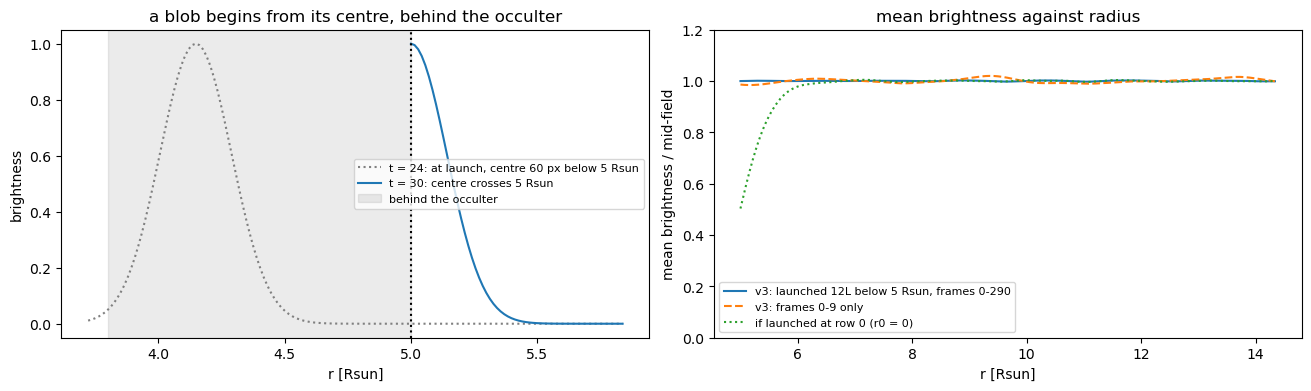

r =  5.00 Rsun: v3 1.000  (frames 0-9: 0.986)   launched at row 0: 0.503
r =  5.14 Rsun: v3 1.000  (frames 0-9: 0.984)   launched at row 0: 0.633
r =  5.28 Rsun: v3 1.001  (frames 0-9: 0.985)   launched at row 0: 0.744
r =  5.57 Rsun: v3 1.000  (frames 0-9: 0.993)   launched at row 0: 0.891
r =  9.68 Rsun: v3 0.998  (frames 0-9: 1.012)   launched at row 0: 0.999
r = 14.08 Rsun: v3 0.999  (frames 0-9: 1.007)   launched at row 0: 0.999
r = 14.34 Rsun: v3 0.999  (frames 0-9: 0.999)   launched at row 0: 1.000


In [5]:
r_enter = (params["syncom_initial_R_sun"] - POLAR_RHO_RANGE[0]) / DR              # where centres enter: pixel 0
print(f"r0 = r_enter - 12 L for every blob: {np.allclose(blobs['r0'], r_enter - 12 * blobs['L'])}")
print(f"launch heights: {to_rsun(blobs['r0']).min():.2f}-{to_rsun(blobs['r0']).max():.2f} Rsun "
      f"(median {np.median(to_rsun(blobs['r0'])):.2f}); hidden for {np.median(-blobs['r0'] / blobs['v']):.0f} frames (median)")

# One test blob at 180 deg: P = 12 frames, v = 10 px/frame, L = 5 px, time_0 = 0, launched 12 L = 60 px below 5 Rsun
one = {"psi": np.array([1800.0]), "r0": np.array([-60.0]), "v": np.array([10.0]),
       "period": np.array([12.0]), "L": np.array([5.0]), "time_0": np.array([0.0])}
one_params = dict(params, syncom_n_blobs=1)

at_launch = syncom_image(one_params, one, time_t=24)[1800]         # launch k = 2 just happened (centre at -60 px)
crossing = syncom_image(one_params, one, time_t=30)[1800]          # 6 frames later its centre is at pixel 0
two_L = int(2 * one["L"][0])
print(f"t = 24 (launch k = 2): brightness at 5 Rsun = {at_launch[0]:.1e} (hidden behind the occulter)")
print(f"t = 30: brightness at 5 Rsun = {crossing[0]:.3f}, one radial width further out = {crossing[two_L]:.4f} (e^-1/2 = {np.exp(-0.5):.4f})")

# Mean radial profile of the full run, averaged over position angle and time (gx from section 2)
def mean_profile(blob_table, steps):
    """Brightness against radius, averaged over position angle and over `steps`, divided by its mid-field value."""
    p = np.mean([syncom_image(params, blob_table, t, gx=gx).mean(axis=0) for t in steps], axis=0)
    return p / p[200:450].mean()

flat_all = mean_profile(blobs, range(0, 300, 10))                  # frames 0, 10, ..., 290
flat_first = mean_profile(blobs, range(0, 10))                     # the first 10 frames only
at_row0 = mean_profile(dict(blobs, r0=np.zeros(N_BLOBS)), range(150, 300, 10))   # same blobs launched at row 0

r = to_rsun(np.arange(NY))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
px = np.arange(-90, 60)                                               # radial pixels, also below the image
ax[0].plot(to_rsun(px), np.exp(-(px - one["r0"][0]) ** 2 / (2 * (2 * one["L"][0]) ** 2)), ":", c="gray",
           label="t = 24: at launch, centre 60 px below 5 Rsun")
ax[0].plot(r[:60], crossing[:60], label="t = 30: centre crosses 5 Rsun")
ax[0].axvline(5.0, c="k", ls=":")
ax[0].axvspan(r[0] - 1.2, 5.0, color="k", alpha=0.08, label="behind the occulter")
ax[0].set(xlabel="r [Rsun]", ylabel="brightness", title="a blob begins from its centre, behind the occulter")
ax[0].legend(fontsize=8)
ax[1].plot(r, flat_all, label="v3: launched 12L below 5 Rsun, frames 0-290")
ax[1].plot(r, flat_first, "--", label="v3: frames 0-9 only")
ax[1].plot(r, at_row0, ":", label="if launched at row 0 (r0 = 0)")
ax[1].set(ylim=(0, 1.2), xlabel="r [Rsun]", ylabel="mean brightness / mid-field", title="mean brightness against radius")
ax[1].legend(fontsize=8)
plt.show()

for x in (0, 10, 20, 40, 330, 640, 658):
    print(f"r = {r[x]:5.2f} Rsun: v3 {flat_all[x]:.3f}  (frames 0-9: {flat_first[x]:.3f})   launched at row 0: {at_row0[x]:.3f}")

assert np.allclose(blobs["r0"], r_enter - 12 * blobs["L"]) and np.isclose(to_rsun(0), 5.0)
assert at_launch[0] < 1e-7                                                                   # hidden at launch
assert np.isclose(crossing[0], 1.0) and np.isclose(crossing[two_L], np.exp(-0.5), atol=1e-6)  # centre at 5 Rsun
assert np.abs(flat_all - 1).max() < 0.05 and np.abs(flat_first - 1).max() < 0.05             # equal at every radius
assert abs(at_row0[0] - 0.5) < 0.05                                                           # the dim ring it avoids

**Observed.** - `r0 = -12L` for all 2000 blobs: launch heights 1.26–4.66 R☉ (median 2.86 R☉), and a blob stays hidden for a median of 19 frames before its centre reaches 5 R☉.
- **Test blob:** at launch ($t = 24$) its brightness at 5 R☉ is $3 \times 10^{-8}$, i.e. it is completely hidden. At $t = 30$ its centre is exactly at 5 R☉ (value 1.000) and one radial width further out the profile is 0.6065 $= e^{-1/2}$. **A blob begins from its centre, behind the occulter.**
- **Equal brightness at every radius** (mean over position angle, divided by the mid-field value):

| r [R☉] | 5.00 | 5.14 | 5.28 | 5.57 | 9.68 | 14.08 | 14.34 |
|---|---|---|---|---|---|---|---|
| v3, frames 0–290 | **1.000** | 1.000 | 1.001 | 1.000 | 0.998 | 0.999 | **0.999** |
| v3, frames 0–9 only | 0.986 | 0.984 | 0.985 | 0.993 | 1.012 | 1.007 | 0.999 |
| launched at row 0 ($r_0 = 0$) | **0.503** | 0.633 | 0.744 | 0.891 | 0.999 | 0.999 | 1.000 |

  The last row is the dim ring that launching at 5 R☉ would produce: exactly half the brightness at the occulter edge, recovering over ≈0.8 R☉, as predicted by $\Phi\big((r - 5\,R_\odot)/2L\big)$. Launching $6 \times 2L$ below removes it. The first 10 frames alone are flat to within 1.6%, the scatter expected from a finite number of blobs.
- The top row is at 14.34 R☉ (5 + 658 × 0.0141876). The plots use the same range, because `POLAR_RHO_RANGE` is computed from `SYNCOM_PIXEL`. ✅

## 4. One blob with $P$ = 1 h: it reappears every period

**Change.** This is the core of v3: a blob reappears **each time its period is up**, for the whole run.

**Physics.** With $P = 12$ frames (1 h at 300 s cadence), $v = 10$ px/frame, $L = 5$ px ($r_0 = -60$ px) and $t_0 = 0$:
- launches happen at $t = \ldots, -12, 0, 12, \ldots, 288$, hidden behind the occulter
- each launch centre crosses 5 R☉ 6 frames later: at $t = 6, 18, \ldots, 294$ (25 crossings in 300 frames)
- launches are $\lambda = vP = 120$ px apart
- each launch takes 66 frames to cross the 659 px field and then leaves

**Expected.**
- A launch centre is exactly at 5 R☉ (brightness 1 at pixel 0) at $t = 6, 18, \ldots, 294$, and at no other frame.
- At $t = 0$ the field is already full: peaks at 60, 180, 300, 420, 540 px, from launches $k = -1 \ldots -5$ made before the first frame, plus one at the top pixel (658): launch $k = -6$ has its centre at 660 px, just above the image, and its inner half still shows.
- At $t = 30$, peaks at 0, 120, 240, 360, 480, 600 px. Launch $k = 2$ is exactly at 5 R☉.
- At $t = 100$, peaks at 100, 220, 340, 460, 580 px (5 launches, 120 px apart).


In [6]:
def peaks(profile, threshold=0.5):
    """Radial pixels of the local maxima above `threshold` (including pixel 0)."""
    p = np.r_[-np.inf, profile, -np.inf]
    return [i for i in range(len(profile)) if p[i + 1] > p[i] and p[i + 1] >= p[i + 2] and profile[i] > threshold]

gx_one = angular_profiles(one_params, one)
rt_one = np.stack([syncom_image(one_params, one, t, gx=gx_one)[1800] for t in FRAMES])   # [time, radius]

crossing_frames = [t for t in FRAMES if np.isclose(rt_one[t, 0], 1.0)]    # a launch centre exactly at 5 Rsun
print("frames when a launch centre crosses 5 Rsun:", crossing_frames)
print("peaks at t = 0:  ", peaks(rt_one[0]), "(launches made before the first frame)")
print("peaks at t = 30: ", peaks(rt_one[30]))
print("peaks at t = 100:", peaks(rt_one[100]), "-> spacing", np.diff(peaks(rt_one[100])))

assert crossing_frames == list(range(6, 300, 12))                         # every period, for the whole run
assert peaks(rt_one[0]) == [60, 180, 300, 420, 540, 658]                  # already full at the first frame (k = -6 leaving at the top)
assert peaks(rt_one[30]) == [0, 120, 240, 360, 480, 600]
assert peaks(rt_one[100]) == [100, 220, 340, 460, 580]

frames when a launch centre crosses 5 Rsun: [np.int64(6), np.int64(18), np.int64(30), np.int64(42), np.int64(54), np.int64(66), np.int64(78), np.int64(90), np.int64(102), np.int64(114), np.int64(126), np.int64(138), np.int64(150), np.int64(162), np.int64(174), np.int64(186), np.int64(198), np.int64(210), np.int64(222), np.int64(234), np.int64(246), np.int64(258), np.int64(270), np.int64(282), np.int64(294)]
peaks at t = 0:   [60, 180, 300, 420, 540, 658] (launches made before the first frame)
peaks at t = 30:  [0, 120, 240, 360, 480, 600]
peaks at t = 100: [100, 220, 340, 460, 580] -> spacing [120 120 120 120]


**Observed.** - A launch centre crosses 5 R☉ at frames **6, 18, 30, …, 294: 25 crossings, exactly once per period for the whole run**. Each launch happened 6 frames earlier ($12L/v = 60/10$), hidden behind the occulter.
- At $t = 0$ the field is already full: peaks at 60, 180, 300, 420 and 540 px from launches made before the first frame, plus the top pixel (658), where launch $k = -6$ (centre at 660 px) is leaving.
- At $t = 30$ the peaks are at 0, 120, 240, 360, 480 and 600 px. Launch $k = 2$ is exactly at 5 R☉.
- At $t = 100$ the peaks are at 100, 220, 340, 460 and 580 px, spaced exactly $vP = 120$ px. ✅

## 5. Periodicity in the cube

**Physics.** A cut through the cube at one position angle, $I(\psi_0, r, t)$, is a **radius–time diagram**.
- Each launch of a blob draws a straight line $r = 5\,R_\odot + \Delta r\,[\,r_0 + v\,(\tau - kP)\,]$. Its slope is the speed. Lines enter at 5 R☉ from below, because launches start behind the occulter.
- Successive launches of the same blob are parallel lines, one period $P$ apart in time.
- At a fixed radius, the brightness repeats every $P$, so its autocorrelation has a peak at lag $P$.

This is the signal that time-delay correlation and FlowTrack use to measure speeds.

The function below draws the diagram, overlays the tracks predicted from the blob table, and plots the light curve at one radius together with its autocorrelation.

It's applied to three cases of increasing complexity:
- **5a.** One blob alone: periodicity is exact.
- **5b.** A sparse run (40 blobs): one blob dominates its position angle.
- **5c.** The full run (2000 blobs): many overlapping trains, from which the wind speed is recovered.


In [7]:
def radial_time_slice(params, blobs, psi_index, steps):
    """
    Radius-time diagram I(psi_index, r, t) of a SynCOM run, computed directly from the model.

    Only the blobs that are bright at this position angle are used (angular weight > 1e-6 of
    their peak), which gives the same column as the full image but is much faster than
    building all 3600 position angles.

    Parameters:
        params: SynCOM parameter dict
        blobs: blob table (syncom_blob_table)
        psi_index: position-angle pixel (0.1 deg each)
        steps: time steps [frames]

    Returns:
        np.ndarray [len(steps), NY]: brightness against time (rows) and radius (columns)
    """
    weight = angular_profiles(params, blobs)[:, psi_index]          # how much each blob shows at psi_index
    near = weight > 1e-6
    sub = {key: values[near] for key, values in blobs.items()}       # blobs that matter here
    sub_params = dict(params, syncom_n_blobs=int(near.sum()))
    gx = angular_profiles(sub_params, sub)
    return np.stack([syncom_image(sub_params, sub, t, gx=gx)[psi_index] for t in steps])


def radial_time_slice_from_fits(fits_dir, run_name, steps, psi_index):
    """Same diagram read from FITS frames written by write_fits_frames (image shape (NY, NX))."""
    return np.stack([fits.getdata(Path(fits_dir) / f"{run_name}_{t:04d}.fts")[:, psi_index] for t in steps])


def autocorrelation(series):
    """Normalised autocorrelation of a time series (lag 0 = 1), for lags 0 ... len-1."""
    s = series - series.mean()
    ac = np.correlate(s, s, mode="full")[len(s) - 1:]
    return ac / ac[0]


def plot_radial_time_slice(rt, steps, title, blob=None, r_probe=300, cadence=CADENCE):
    """
    Plot a radius-time diagram, the light curve at one radius and its autocorrelation.

    Parameters:
        rt: [len(steps), NY] diagram (radial_time_slice or radial_time_slice_from_fits)
        steps: time steps of the rows of rt [frames]
        title: figure title
        blob: optional dict with this blob's 'v', 'period', 'r0', 'time_0' (scalars) -> its
              predicted launch tracks r = r0 + v (tau - k P) are drawn as dashed lines,
              and lag P is marked on the autocorrelation
        r_probe: radial pixel of the light curve
    Returns:
        lag_of_peak: lag [frames] of the highest autocorrelation peak after lag 0
    """
    hours = np.asarray(steps) * cadence / 3600
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout="constrained", gridspec_kw={"width_ratios": [2, 1.3, 1]})

    # (a) radius-time diagram
    ax[0].imshow(rt.T, origin="lower", aspect="auto", cmap=cmap_punch,
                 extent=[hours[0], hours[-1], *to_rsun([0, rt.shape[1] - 1])])
    if blob is not None:                                       # predicted tracks of every launch k
        tau = np.asarray(steps) + blob["time_0"]
        k_first = int(np.floor((blob["r0"] + blob["v"] * tau.min() - rt.shape[1]) / (blob["v"] * blob["period"])))
        for k in range(k_first, int(tau.max() // blob["period"]) + 1):    # k < 0: launched before the first step
            r = blob["r0"] + blob["v"] * (tau - k * blob["period"])
            ok = (tau >= k * blob["period"]) & (r >= 0) & (r <= rt.shape[1] - 1)
            ax[0].plot(hours[ok], to_rsun(r[ok]), "w--", lw=0.8)
    ax[0].axhline(to_rsun(r_probe), c="c", lw=0.8)
    ax[0].set(xlabel="time [h]", ylabel="r [Rsun]", title="radius-time diagram (dashed: predicted launches)")

    # (b) light curve at r_probe
    curve = rt[:, r_probe]
    ax[1].plot(hours, curve)
    ax[1].set(xlabel="time [h]", ylabel="brightness", title=f"light curve at r = {to_rsun(r_probe):.2f} Rsun")

    # (c) autocorrelation of the light curve
    ac = autocorrelation(curve)
    lags = np.arange(len(ac))
    is_peak = (ac[1:-1] > ac[:-2]) & (ac[1:-1] >= ac[2:])
    peak_lags = lags[1:-1][is_peak]
    lag_of_peak = int(peak_lags[np.argmax(ac[1:-1][is_peak])]) if is_peak.any() else None
    ax[2].plot(lags * cadence / 3600, ac)
    if blob is not None:
        ax[2].axvline(blob["period"] * cadence / 3600, c="r", ls="--", label=f"P = {blob['period'] * cadence / 3600:.2f} h")
        ax[2].legend()
    ax[2].set(xlim=(0, 4 * (blob["period"] if blob else 12) * cadence / 3600), xlabel="lag [h]", title="autocorrelation")

    fig.suptitle(title)
    plt.show()
    return lag_of_peak

### 5a. The single test blob ($P$ = 1 h, $v$ = 10 px/frame)

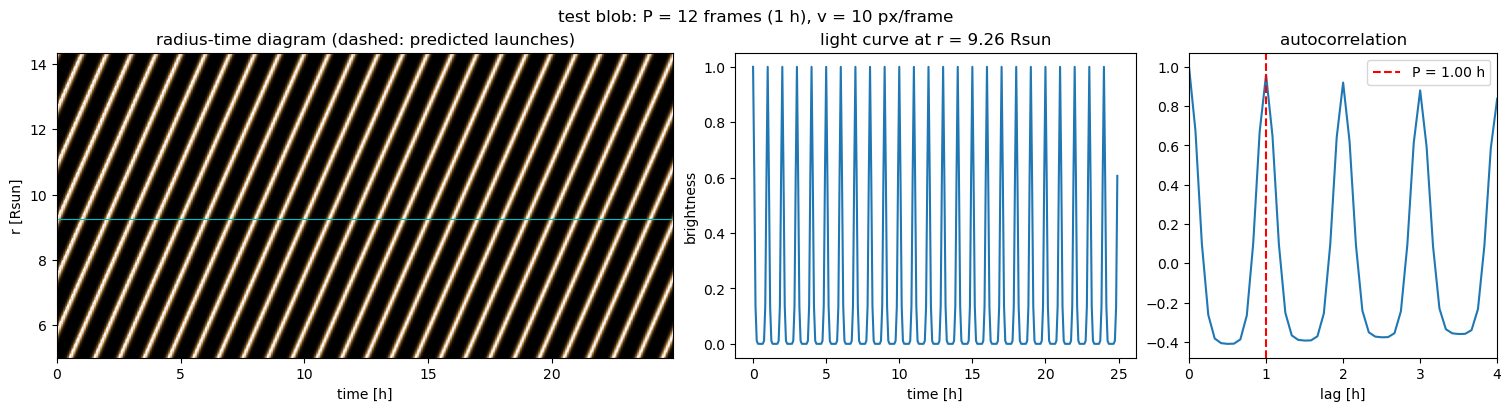

autocorrelation peak at lag 12 frames


In [8]:
lag = plot_radial_time_slice(rt_one, FRAMES, "test blob: P = 12 frames (1 h), v = 10 px/frame",
                             blob={k: v[0] for k, v in one.items()})
print("autocorrelation peak at lag", lag, "frames")
assert lag == 12

### 5b. A sparse run: 40 blobs, the same model
With few blobs, each position angle is dominated by a single blob, so its own periodicity can be read off the cube. This run uses exactly the same functions (`syncom_load` → `syncom_blob_table` → `syncom_image`) with `SYNCOM_N_BLOBS=40`. The cell picks the most isolated blob.

**Expected.** Streaks on the predicted tracks, and an autocorrelation peak at the blob's period $P$. $P$ isn't a whole number of frames and the light curve is sampled once per frame, so the peak can fall up to about one frame from $P$. The test allows ±1.5 frames.


No file or date entered. Using default: syncom_20140414_densfix.sav


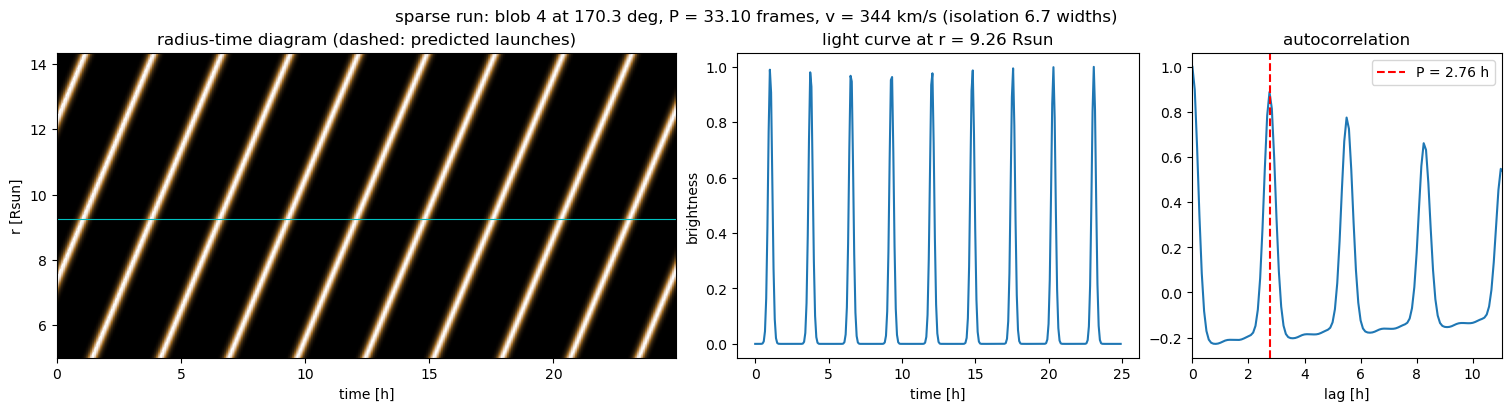

P = 33.10 frames, autocorrelation peak at lag 33 frames


In [9]:
params_40 = default_syncom_prams(SYNCOM_N_BLOBS=40, SYNCOM_SCALE_FACTOR=SCALE)
blobs_40 = syncom_blob_table(params_40, syncom_load(params_40, simple=True), SCALE)

def isolation(blob_table, i):
    """Gap between blob i and its nearest neighbour, in units of their summed widths (> 3: well separated)."""
    psi, L = blob_table["psi"], blob_table["L"]
    others = np.delete(np.arange(len(psi)), i)
    gap = np.abs((psi[others] - psi[i] + 1800) % 3600 - 1800)        # angular distance on the circle [px]
    return np.min(gap / (L[others] + L[i]))

i40 = max(range(40), key=lambda i: isolation(blobs_40, i))
b40 = {k: v[i40] for k, v in blobs_40.items()}
rt_40 = radial_time_slice(params_40, blobs_40, int(b40["psi"]), FRAMES)
lag_40 = plot_radial_time_slice(rt_40, FRAMES, f"sparse run: blob {i40} at {b40['psi'] / 10:.1f} deg, "
                                f"P = {b40['period']:.2f} frames, v = {b40['v'] * DR * 696000 / CADENCE:.0f} km/s "
                                f"(isolation {isolation(blobs_40, i40):.1f} widths)", blob=b40)
print(f"P = {b40['period']:.2f} frames, autocorrelation peak at lag {lag_40} frames")
assert abs(lag_40 - b40["period"]) <= 1.5

### 5c. The full run (2000 blobs): many overlapping trains, one wind speed
With 2000 blobs, **50–80 blobs overlap at every position angle**. Blobs are on average 0.18° apart but up to 2.2° wide. The light curve at one angle is a sum of dozens of periodic sources with periods from 18 to 36 frames. Its autocorrelation has peaks at many of these periods, so the period of a single blob can't be read from it. The plot marks the periods of the strongest contributors.

What does survive the overlap is the **speed**. The wind speed depends only on position angle, and it changes by only about 2 km/s per degree, so all the overlapping blobs move at nearly the same speed. A brightness pattern seen at $r_1$ reaches $r_2$ a time

$$\Delta t = \frac{r_2 - r_1}{v}$$

later, so the cross-correlation of the two light curves peaks at that lag. This is the time-delay correlation method.

**Expected.** In both sectors, the speed recovered from the cross-correlation lag between $r_1 = 150$ px and $r_2 = 450$ px agrees with the input speed $v(\psi)$ to within 5%. The fast sector ($\psi \approx 180^\circ$) gives about twice the speed of the slow sector ($\psi \approx 90^\circ$).


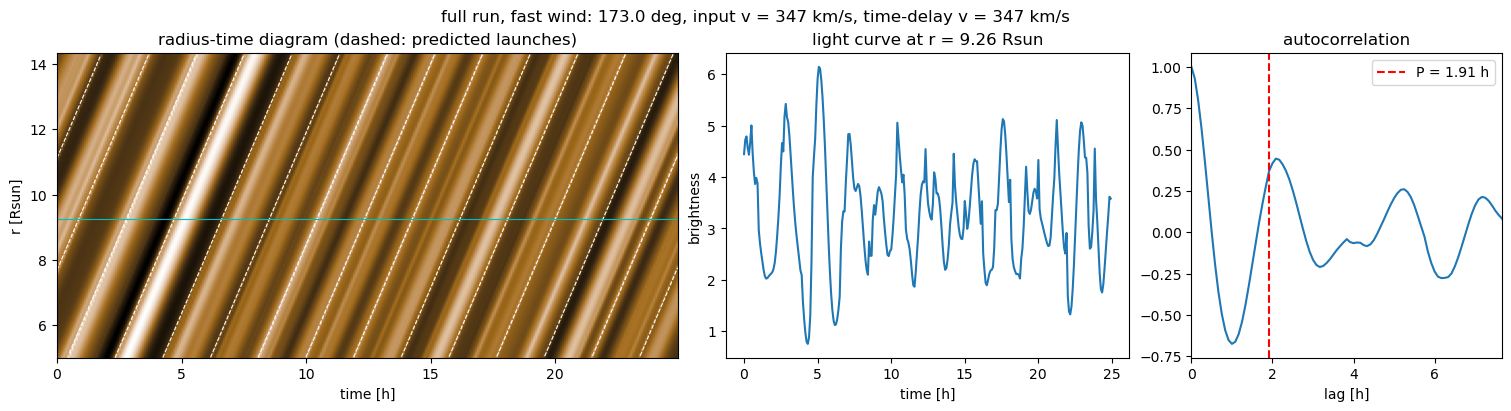

fast wind: 51 blobs contribute at 173.0 deg; strongest periods [23.  25.4 21.3 21.2 24.9] frames (weights [1.   0.97 0.96 0.93 0.75])
   input v = 347.0 km/s, time-delay v = 347.1 km/s (+0.0%)


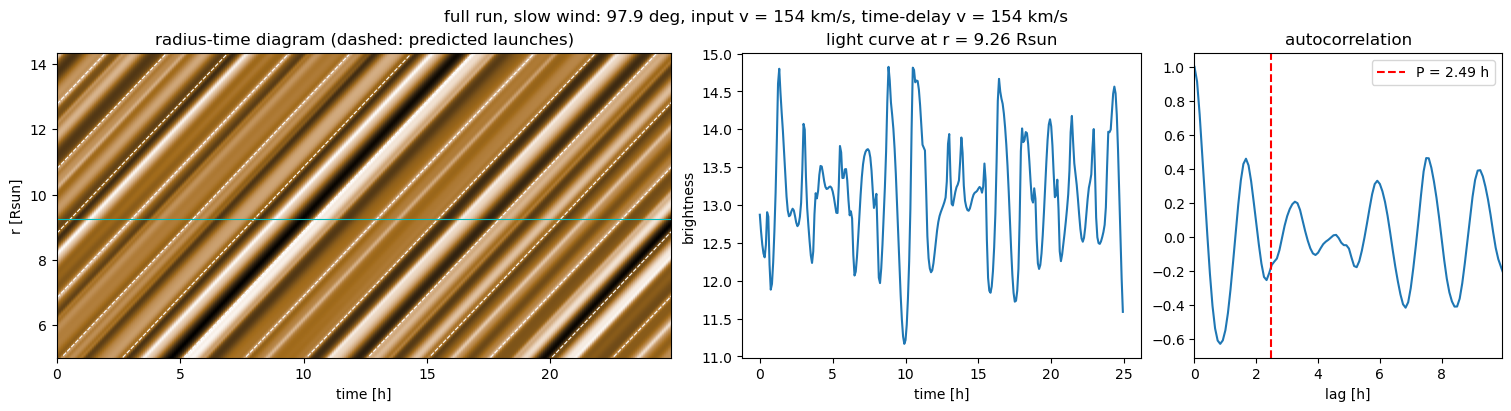

slow wind: 83 blobs contribute at 97.9 deg; strongest periods [29.8 21.4 33.3 22.4 22.8] frames (weights [1.   0.98 0.98 0.97 0.97])
   input v = 153.8 km/s, time-delay v = 154.1 km/s (+0.2%)


In [10]:
def delay_speed(rt, r1, r2, max_lag=150):
    """
    Speed [px/frame] from the time delay between the light curves at radial pixels r1 < r2.
    The lag of the cross-correlation peak is refined to sub-frame precision with a parabola
    through the peak and its two neighbours.
    """
    a = rt[:, r1] - rt[:, r1].mean()
    b = rt[:, r2] - rt[:, r2].mean()
    lags = np.arange(1, max_lag)
    cc = np.array([np.sum(a[:-lag] * b[lag:]) for lag in lags])      # b later than a by `lag` frames
    k = np.argmax(cc)
    shift = 0.5 * (cc[k - 1] - cc[k + 1]) / (cc[k - 1] - 2 * cc[k] + cc[k + 1])
    return (r2 - r1) / (lags[k] + shift)

def most_isolated_near(target_deg, window_deg=10):
    """Blob of the full run within +-window_deg of target_deg with the largest gap to its neighbours."""
    d = np.abs((blobs["psi"] - target_deg * 10 + 1800) % 3600 - 1800)
    return max(np.where(d <= window_deg * 10)[0], key=lambda i: isolation(blobs, i))

speeds = {}
for name, target in (("fast wind", 180), ("slow wind", 90)):
    i = most_isolated_near(target)
    b = {k: v[i] for k, v in blobs.items()}
    rt = radial_time_slice(params, blobs, int(b["psi"]), FRAMES)
    v_true = b["v"] * DR * 696000 / CADENCE                       # input speed at this position angle [km/s]
    v_meas = delay_speed(rt, 150, 450) * DR * 696000 / CADENCE     # speed recovered from the cube [km/s]
    speeds[name] = (v_true, v_meas)

    plot_radial_time_slice(rt, FRAMES, f"full run, {name}: {b['psi'] / 10:.1f} deg, input v = {v_true:.0f} km/s, "
                           f"time-delay v = {v_meas:.0f} km/s", blob=b)
    weight = angular_profiles(params, blobs)[:, int(b["psi"])]
    strong = np.argsort(weight)[::-1][:5]
    print(f"{name}: {np.sum(weight > 1e-6)} blobs contribute at {b['psi'] / 10:.1f} deg; strongest periods "
          f"{np.round(blobs['period'][strong], 1)} frames (weights {np.round(weight[strong], 2)})")
    print(f"   input v = {v_true:.1f} km/s, time-delay v = {v_meas:.1f} km/s ({100 * (v_meas / v_true - 1):+.1f}%)")

for name, (v_true, v_meas) in speeds.items():
    assert abs(v_meas / v_true - 1) < 0.05, (name, v_true, v_meas)
assert speeds["fast wind"][1] > 1.8 * speeds["slow wind"][1]

**Observed.** - **5a. One blob:** the autocorrelation peaks at exactly 12 frames (= $P$). The radius–time diagram shows parallel streaks on the predicted centre tracks for the whole run, including at $t = 0$, where launches made before the first frame are already in the field.
- **5b. Sparse run:** blob 4 at 170.3° ($P$ = 33.10 frames = 2.76 h, $v$ = 344 km/s, 6.7 widths from its nearest neighbour).
  - Nine parallel streaks on the predicted tracks. At $t = 0$ the first streak is already at ≈12 R☉.
  - The light curve shows one pulse per period, all of the same height.
  - The autocorrelation peaks at 33 frames and at its multiples.
- **5c. Full run:** 51 blobs (at 173.0°) and 83 blobs (at 97.9°) contribute.
  - The autocorrelation shows several peaks, because periods of 21–33 frames are mixed together, so no single period dominates. This is the expected result of overlap, not an error; section 6 extracts the frequencies with the Fourier power spectrum instead.
  - The streaks all have the same slope, and the speed recovered by time-delay correlation matches the input:

| sector | input $v(\psi)$ | time-delay speed from the cube | error |
|---|---|---|---|
| fast wind (173.0°) | 347.0 km/s | 347.1 km/s | +0.0% |
| slow wind (97.9°) | 153.8 km/s | 154.1 km/s | +0.2% |

- Compared with the earlier v3 (launch at 5 R☉), the diagrams have **no dark wedge** at the start (no spin-up) and **no dark band along 5 R☉** (blobs enter fully formed). ✅

## 6. Frequencies in the images against `syncom_load`: the Fourier power spectrum

**Question.** `syncom_load` gives every 0.1° position-angle bin a period $P$, drawn uniformly between 1.5 and 3 h (18–36 frames), and every blob takes the period of its bin. Are these the frequencies that actually appear in the images? And what is the best tool to extract them?

**Physics: the spectrum of a blob train.** At a fixed radius, one blob produces a train of Gaussian pulses in time: one pulse per launch, every $P$ frames. Each pulse lasts $\sigma_t = 2L/v$ frames (the radial width divided by the speed). A periodic train of Gaussian pulses has the Fourier series

$$
s(t) = \frac{\sigma_t\sqrt{2\pi}}{P}\left[1 + 2\sum_{n \ge 1} e^{-2\pi^2 n^2 \sigma_t^2 / P^2}\cos\!\left(\frac{2\pi n\,(t - t_0)}{P}\right)\right],
$$

so its Fourier power spectrum is a set of **lines** at the frequency $f = 1/P$ and its harmonics $n/P$. Short pulses (small $\sigma_t/P$) have strong harmonics, and long pulses have almost only the fundamental. The image is a sum over blobs, each weighted by its angular profile $w_b(\psi)$. Blobs have different periods, so in a long record their cross terms average out and their **powers add**: the spectrum at angle $\psi$ is the sum of every contributing blob's lines.

**Resolution.** A record of length $T$ resolves frequencies $\Delta f = 1/T$ apart (the Rayleigh criterion). The run lasts $T = 300$ frames (25 h), so $\Delta f = 1/300$ per frame (0.011 mHz). The `syncom_load` band $1/36$ to $1/18$ per frame (0.093–0.185 mHz) is only about 8 resolution elements wide. With 50–80 blobs overlapping at each position angle (section 5c), several blobs share each resolution element, so the period of one blob can be read off only where that blob dominates its angle.

**Choosing the tool.**

| tool | how it finds a period | verdict for SynCOM |
|---|---|---|
| autocorrelation | first strong peak in lag | finds one period; a sum of sources gives a mixture of peaks (section 5c). Precision limited to about 0.04 frames |
| Lomb–Scargle periodogram | least-squares sine fit at each trial frequency | designed for uneven sampling. The frames are evenly spaced, so it reduces to the Fourier power spectrum |
| wavelet transform | power against time and frequency | for periods that change with time. SynCOM periods are constant, so it only loses frequency resolution |
| **Fourier power spectrum** $\lvert\mathrm{DFT}\rvert^2$ **with Hann window, zero padding and peak interpolation** | power at every frequency | **chosen**: separates superposed sources into separate lines, the powers add, so the whole spectrum can be **predicted from `syncom_load`** and compared, and it is the most precise |

The Hann window suppresses leakage from strong lines into weak ones. Zero padding (to 8192 points) samples the spectrum finely, and a parabola through the three highest points gives the peak to a fraction of a resolution element. All of this needs a **stationary** record, and v3 is in steady state from frame 0 (section 2), so the whole 300-frame run can be used.

**Expected.**
- **6a. Dominant blobs (sparse 40-blob run):** for each blob that makes at least 95% of the light at its own position angle, the Fourier power spectrum of the light curve there peaks at its `syncom_load` period to within 0.1 frame. The tools are compared on the same blobs.
- **6b. The full run (2000 blobs):** the mean Fourier power spectrum over all 3600 position angles matches the spectrum predicted from the `syncom_load` periods, speeds and sizes, in shape (correlation > 0.98) and in absolute power (within 10%). Scaling every period by a factor $s$ and repeating the comparison gives the best match at $s = 1$ (within 1%). So the frequencies in the images are the ones in `syncom_load`.


sparse run: 16 of 40 blobs make at least 95% of the light at their own position angle
tool                                                    dominant blobs within 0.1 frame   median |error| [frames]   all 40 within 0.5 frame
Fourier power spectrum (Hann, zero padding, parabola)    16 / 16                    0.001                    31 / 40
Lomb-Scargle                                             16 / 16                    0.009                    32 / 40
autocorrelation                                          15 / 16                    0.037                    34 / 40


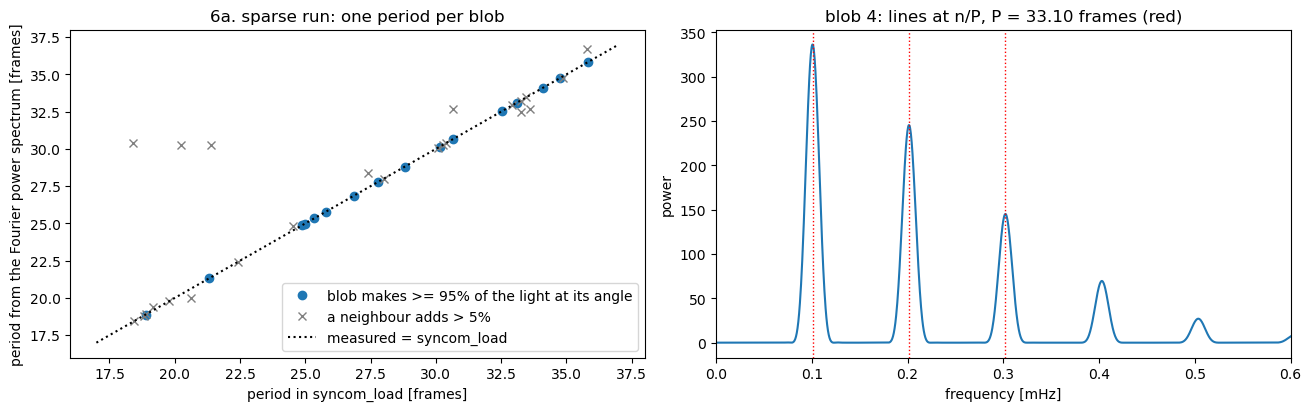

In [11]:
T = len(FRAMES)
NFFT = 8192                                    # zero padding: spectrum sampled every 1/8192 per frame
freq = np.fft.rfftfreq(NFFT)                   # [cycles per frame]; mHz = freq / CADENCE * 1e3
hann = np.hanning(T)


def fourier_power_spectrum(series):
    """Fourier power spectrum |DFT|^2 of a light curve (mean removed, Hann window, zero padded to NFFT)."""
    return np.abs(np.fft.rfft((series - series.mean()) * hann, n=NFFT)) ** 2


def peak_period(power, p_min=15, p_max=45):
    """
    Period [frames] of the highest Fourier-power peak with p_min < P < p_max, refined by a parabola
    through the log-power of the peak and its two neighbours (sub-resolution precision).
    """
    band = (freq > 1 / p_max) & (freq < 1 / p_min)
    k = np.argmax(np.where(band, power, 0))
    y0, y1, y2 = np.log(power[k - 1:k + 2])
    return NFFT / (k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2))


def acf_period(series, p_min=15, p_max=45):
    """Period [frames] from the highest autocorrelation peak with p_min < lag < p_max (parabola-refined)."""
    ac = autocorrelation(series)
    k = p_min + np.argmax(ac[p_min:p_max + 1])
    y0, y1, y2 = ac[k - 1:k + 2]
    return k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)


def lomb_scargle_period(series, p_min=15, p_max=45):
    """Period [frames] of the highest Lomb-Scargle peak on a fine frequency grid."""
    from astropy.timeseries import LombScargle
    trial = np.linspace(1 / p_max, 1 / p_min, 4000)
    return 1 / trial[np.argmax(LombScargle(np.arange(T), series).power(trial))]


# 6a. Sparse run: light curve of every blob at its own position angle, at r = 300 px
R_PROBE = 300
gx_40 = angular_profiles(params_40, blobs_40)
lc_40 = np.stack([syncom_image(params_40, blobs_40, t, gx=gx_40)[:, R_PROBE] for t in FRAMES])      # [time, psi]
# Share of the light at blob i's own position angle that comes from blob i (1 = alone there)
own_share = np.array([gx_40[i, int(blobs_40["psi"][i])] / gx_40[:, int(blobs_40["psi"][i])].sum() for i in range(40)])
isolated = own_share >= 0.95                                           # the blob dominates its position angle

tools = {"Fourier power spectrum (Hann, zero padding, parabola)": lambda x: peak_period(fourier_power_spectrum(x)),
         "Lomb-Scargle": lomb_scargle_period,
         "autocorrelation": acf_period}
errors = {name: np.array([tool(lc_40[:, int(blobs_40["psi"][i])]) - blobs_40["period"][i] for i in range(40)])
          for name, tool in tools.items()}

print(f"sparse run: {isolated.sum()} of 40 blobs make at least 95% of the light at their own position angle")
print(f"{'tool':55s} dominant blobs within 0.1 frame   median |error| [frames]   all 40 within 0.5 frame")
for name, err in errors.items():
    print(f"{name:55s} {np.sum(np.abs(err[isolated]) < 0.1):3d} / {isolated.sum()}"
          f"                    {np.median(np.abs(err[isolated])):.3f}                   {np.sum(np.abs(err) < 0.5):3d} / 40")

best = errors["Fourier power spectrum (Hann, zero padding, parabola)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax[0].plot(blobs_40["period"][isolated], (blobs_40["period"] + best)[isolated], "o", label="blob makes >= 95% of the light at its angle")
ax[0].plot(blobs_40["period"][~isolated], (blobs_40["period"] + best)[~isolated], "x", c="gray", label="a neighbour adds > 5%")
ax[0].plot([17, 37], [17, 37], "k:", label="measured = syncom_load")
ax[0].set(xlabel="period in syncom_load [frames]", ylabel="period from the Fourier power spectrum [frames]", title="6a. sparse run: one period per blob")
ax[0].legend()
i_show = int(np.argmax(own_share * (blobs_40["L"] > 5)))                # a dominant blob with visible harmonics
ax[1].plot(freq / CADENCE * 1e3, fourier_power_spectrum(lc_40[:, int(blobs_40["psi"][i_show])]))
for n in (1, 2, 3):
    ax[1].axvline(n / blobs_40["period"][i_show] / CADENCE * 1e3, c="r", ls=":", lw=1)
ax[1].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power",
          title=f"blob {i_show}: lines at n/P, P = {blobs_40['period'][i_show]:.2f} frames (red)")
plt.show()

assert np.all(np.abs(best[isolated]) < 0.1)                                      # dominant blobs: exact periods

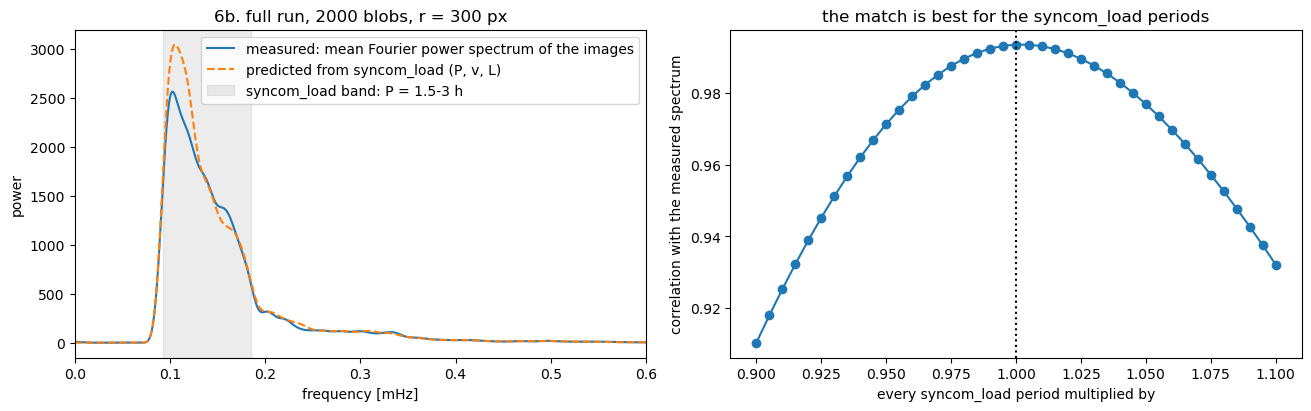

measured vs predicted: correlation 0.9935, total power ratio 0.931
best period scale 1.000; correlation at 0.95 / 1.00 / 1.05: 0.9713 / 0.9935 / 0.9769


In [12]:
# 6b. Full run: light curves at r = 300 px for all 3600 position angles, 300 frames
lc = np.stack([syncom_image(params, blobs, t, gx=gx)[:, R_PROBE] for t in FRAMES])     # [time, psi]
measured = np.mean([fourier_power_spectrum(lc[:, psi]) for psi in range(NX)], axis=0)              # mean over position angle


def predicted_spectrum(period_scale=1.0, n_harmonics=7):
    """
    Mean Fourier power spectrum predicted from the blob table alone (no images): every blob b adds lines at
    n / P_b with cosine amplitude a_bn = 2 (sigma_t sqrt(2 pi) / P) exp(-2 pi^2 n^2 sigma_t^2 / P^2),
    sigma_t = 2 L / v, weighted by sum_psi w_b(psi)^2 (its angular profile), and each line is
    spread by the Hann window response |W(f)|^2. A cosine of amplitude a has power (a / 2)^2 |W|^2.
    period_scale multiplies every period (a control: the match should be best at 1).
    """
    period = blobs["period"] * period_scale
    sigma_t = 2 * blobs["L"] / blobs["v"]
    n = np.arange(1, n_harmonics + 1)[:, None]
    amplitude = 2 * sigma_t * np.sqrt(2 * np.pi) / period * np.exp(-2 * np.pi ** 2 * n ** 2 * sigma_t ** 2 / period ** 2)
    weight = (gx ** 2).sum(axis=1)                                                   # sum over psi of w_b(psi)^2
    df = np.arange(-0.03, 0.03, 0.25 / NFFT)                                         # window response |W(df)|^2
    window_power = np.abs(np.exp(-2j * np.pi * df[:, None] * np.arange(T)) @ hann) ** 2
    spectrum = np.zeros_like(freq)
    for f_line, power in zip((n / period).ravel(), ((amplitude / 2) ** 2 * weight).ravel()):
        spectrum += power * np.interp(freq - f_line, df, window_power, left=0, right=0)
    return spectrum / NX


band = (freq > 0.01) & (freq < 0.2)                                                  # periods 5-100 frames
prediction = predicted_spectrum()
corr = np.corrcoef(measured[band], prediction[band])[0, 1]
ratio = measured[band].sum() / prediction[band].sum()
scales = np.round(np.arange(0.90, 1.101, 0.005), 3)
scan = np.array([np.corrcoef(measured[band], predicted_spectrum(s)[band])[0, 1] for s in scales])

fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
mhz = freq / CADENCE * 1e3
ax[0].plot(mhz, measured, label="measured: mean Fourier power spectrum of the images")
ax[0].plot(mhz, prediction, "--", label="predicted from syncom_load (P, v, L)")
ax[0].axvspan(1 / 36 / CADENCE * 1e3, 1 / 18 / CADENCE * 1e3, color="gray", alpha=0.15, label="syncom_load band: P = 1.5-3 h")
ax[0].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power", title="6b. full run, 2000 blobs, r = 300 px")
ax[0].legend()
ax[1].plot(scales, scan, "o-")
ax[1].axvline(1.0, c="k", ls=":")
ax[1].set(xlabel="every syncom_load period multiplied by", ylabel="correlation with the measured spectrum",
          title="the match is best for the syncom_load periods")
plt.show()

print(f"measured vs predicted: correlation {corr:.4f}, total power ratio {ratio:.3f}")
print(f"best period scale {scales[np.argmax(scan)]:.3f}; correlation at 0.95 / 1.00 / 1.05: "
      f"{scan[scales == 0.95][0]:.4f} / {scan[scales == 1.0][0]:.4f} / {scan[scales == 1.05][0]:.4f}")
assert corr > 0.98 and abs(ratio - 1) < 0.10
assert abs(scales[np.argmax(scan)] - 1) <= 0.01

**Observed.** - **6a. Choosing the tool (sparse run).** 16 of the 40 blobs make at least 95% of the light at their own position angle:

| tool | dominant blobs within 0.1 frame of the `syncom_load` period | median error | all 40 blobs within 0.5 frame |
|---|---|---|---|
| **Fourier power spectrum** (Hann window, zero padding, parabola) | **16 / 16** | **0.001 frames** | 31 / 40 |
| Lomb–Scargle | 16 / 16 | 0.009 frames | 32 / 40 |
| autocorrelation | 15 / 16 | 0.037 frames | 34 / 40 |

  The Fourier power spectrum is the most precise: 0.001 frames is 0.3 s on a period of hours. Its spectrum shows the expected lines at $n/P$, getting weaker with $n$ as $e^{-2\pi^2 n^2 \sigma_t^2/P^2}$. The blobs it misses are those where a neighbour adds more than 5% of the light: several are pulled to the same neighbour's period (≈30.3 frames). No tool can assign a period to a blob that doesn't dominate its own light curve.
- **6b. Full run (2000 blobs).** The mean Fourier power spectrum over all 3600 position angles agrees with the spectrum predicted from the `syncom_load` periods, speeds and sizes alone:
  - shape: correlation **0.9935**
  - power: the measured total is 7% below the prediction (ratio 0.931), mostly at the strongest peak near 0.1 mHz. The cause wasn't investigated; it doesn't move the frequencies.
  - frequency: scaling every `syncom_load` period by $s$ gives the best match at **$s = 1.000$**. The correlation drops to 0.971 at $s = 0.95$ and 0.977 at $s = 1.05$.
  - 82% of the power lies in the `syncom_load` band $P$ = 1.5–3 h (0.093–0.185 mHz). The rest is the harmonics $n/P$ of short pulses.

**So the frequencies in the images are the ones put in by `syncom_load`.** The best tool to extract them is the Fourier power spectrum. With heavy overlap it gives the population of periods rather than one period per position angle. ✅

### 6c. The run of the main notebook: `SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0`

**Question.** The main notebook runs 5 times more blobs than the reference run of 6b, each half as wide (10000 blobs, scale factor 1, 500 frames). Does that make the periods easier to read?

**Physics: how much the blobs overlap.** The light at one position angle is a sum over blobs weighted by their angular profiles $w_b(\psi)$. A useful measure of how many blobs share that light is the **effective number**

$$
N_\text{eff}(\psi) = \frac{\left(\sum_b w_b(\psi)\right)^2}{\sum_b w_b(\psi)^2},
$$

which is 1 when one blob makes all the light and $n$ when $n$ blobs contribute equally. The blobs are spread uniformly in angle, so $N_\text{eff} \propto N \langle L \rangle$: the number of blobs per degree times their width. Going from 2000 blobs at scale 2 to 10000 blobs at scale 1 multiplies $N \langle L \rangle$ by $5 / 2 = 2.5$. **Smaller blobs, but many more of them, means more overlap, not less.**

**Physics: frequency resolution.** 500 frames resolve frequencies $1/500$ per frame apart, instead of $1/300$. The `syncom_load` band (1/36 to 1/18 per frame) then spans about 14 resolution elements instead of 8. That helps separate lines, but only if there are fewer lines than resolution elements at each angle.

**Expected.**
- $N_\text{eff}$ about 2.5 times larger than in the 2000-blob run, and no blob that makes 95% of the light at its own angle.
- The strongest line at one angle matches the strongest line predicted there no more often than in the 2000-blob run: one period per angle can't be read.
- The **population** of periods is still exactly the `syncom_load` one, and better measured, because 10000 blobs sample the period distribution more densely: correlation > 0.98 between the measured and predicted mean spectra, power within 10%, best period scale within 1% of 1.

The cell reads the light curves at $r$ = 300 px from the run's saved cube, with the run's own parameters and blob table (stored in the `.npz`). If the cube isn't on this computer, it rebuilds the same light curves from the model.


loaded SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0_cube.npz: (3600, 659, 500); light curves match the model to 3.6e-14
10000 blobs, scale factor 1.0, 500 frames; L = 1.0-11.0 px
                                                       2000 blobs, scale 2    10000 blobs, scale 1
frames / resolution elements in the P = 1.5-3 h band               300 / 8                500 / 14
effective number of blobs per angle (median)                          24.3                    58.9
blobs making >= 95% of the light at their angle                          0                       0
angles whose strongest line is the predicted one                       42%                     31%
mean spectrum: correlation with syncom_load                         0.9935                  0.9933
mean spectrum: measured / predicted power                            0.931                   1.007
best period scale                                                    1.000                   1.005


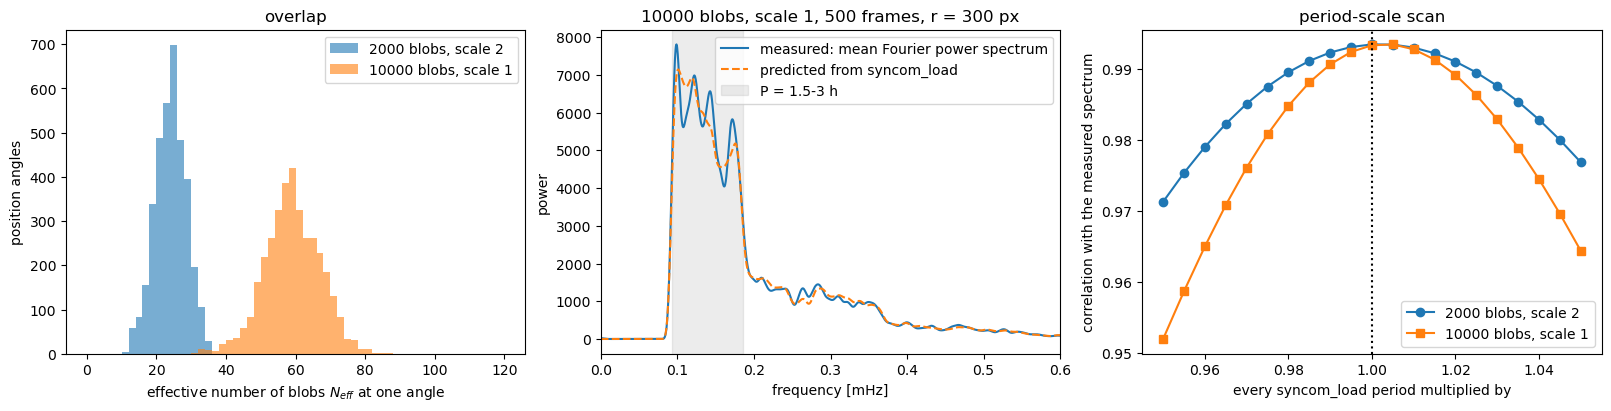

In [13]:
RUN_31 = "SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0"


def light_curves_at(run_params, run_blobs, r_px, steps):
    """
    Brightness at radial pixel r_px for every position angle and time step, [len(steps), NX].
    Same model as syncom_image (every launch k_lo..k_hi of every blob), evaluated at one radius only.
    """
    radial = np.zeros((len(run_blobs["v"]), len(steps)))
    for j, t in enumerate(steps):
        tau, k_lo, k_hi = launch_range(run_blobs, t, run_params["syncom_ny"])
        for k in range(int(k_lo.min()), int(k_hi.max()) + 1):
            centre = run_blobs["r0"] + run_blobs["v"] * (tau - k * run_blobs["period"])
            on = (k >= k_lo) & (k <= k_hi)
            radial[:, j] += np.where(on, np.exp(-(r_px - centre) ** 2 / (2 * (2 * run_blobs["L"]) ** 2)), 0.0)
    return (angular_profiles(run_params, run_blobs).T @ radial).T


def load_run(run_name, n_blobs, scale, n_frames, r_px=R_PROBE):
    """
    Parameters, blob table and light curves [time, psi] at r_px of a saved run.
    Reads the run's cube (with its own params and LoadStruc) when it is on this computer;
    otherwise rebuilds the same light curves from the model (n_blobs, scale, n_frames, simple=True).
    """
    cube_file = syncom_run_dir(run_name, "cubes") / f"{run_name}_cube.npz"
    if cube_file.exists():                                   # about 9.5 GB in memory while loading 500 frames
        saved = np.load(cube_file, allow_pickle=True)
        run_params, run_scale = saved["params"].item(), float(saved["scale_factor"])
        run_blobs = syncom_blob_table(run_params, saved["LoadStruc"].item(), run_scale)
        cube = saved["syncom_data"]
        run_lc = np.ascontiguousarray(cube[:, r_px, :].T)
        check = light_curves_at(run_params, run_blobs, r_px, [0, cube.shape[2] - 1])
        print(f"loaded {cube_file.name}: {cube.shape}; light curves match the model to "
              f"{np.abs(check - run_lc[[0, -1]]).max():.1e}")
        del cube, saved
    else:                                                    # same run, rebuilt from the model at r = r_px
        run_params = default_syncom_prams(SYNCOM_N_BLOBS=n_blobs, SYNCOM_SCALE_FACTOR=scale)
        run_scale = scale
        run_blobs = syncom_blob_table(run_params, syncom_load(run_params, simple=True), run_scale)
        run_lc = light_curves_at(run_params, run_blobs, r_px, range(n_frames))
        print(f"{cube_file.name} not found: light curves rebuilt from the model")
    return run_params, run_scale, run_blobs, run_lc


params_31, scale_31, blobs_31, lc_31 = load_run(RUN_31, 10000, 1.0, 500)
T_31 = lc_31.shape[0]
gx_31 = angular_profiles(params_31, blobs_31)
print(f"{params_31['syncom_n_blobs']} blobs, scale factor {scale_31}, {T_31} frames; L = {blobs_31['L'].min():.1f}-{blobs_31['L'].max():.1f} px")


def frequency_report(run_blobs, run_gx, run_lc, n_harmonics=7):
    """
    Frequency analysis of one run from its light curves run_lc [time, psi] at one radius.

    Returns a dict with: the effective number of overlapping blobs per angle, the blobs that make
    >= 95 % of the light at their own angle and the error of their periods, the share of angles whose
    strongest Fourier line is the predicted strongest line, and the mean spectrum measured and
    predicted from the blob table (with the period-scale scan).
    """
    n_t = run_lc.shape[0]
    window = np.hanning(n_t)
    spec = np.abs(np.fft.rfft((run_lc - run_lc.mean(axis=0)) * window[:, None], n=NFFT, axis=0)) ** 2   # [freq, psi]
    band = (freq > 0.01) & (freq < 0.2)

    weight_sum = run_gx.sum(axis=0)
    n_eff = weight_sum ** 2 / (run_gx ** 2).sum(axis=0)
    psi_b = run_blobs["psi"].astype(int)
    share = run_gx[np.arange(len(psi_b)), psi_b] / weight_sum[psi_b]
    dominant = np.where(share >= 0.95)[0]

    def peak(power):
        b = (freq > 1 / 45) & (freq < 1 / 15)
        k = np.argmax(np.where(b, power, 0))
        y0, y1, y2 = np.log(power[k - 1:k + 2])
        return NFFT / (k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2))
    period_error = np.array([peak(spec[:, psi_b[i]]) - run_blobs["period"][i] for i in dominant])

    sigma_t = 2 * run_blobs["L"] / run_blobs["v"]
    n = np.arange(1, n_harmonics + 1)[:, None]
    df = np.arange(-0.03, 0.03, 0.25 / NFFT)
    window_power = np.abs(np.exp(-2j * np.pi * df[:, None] * np.arange(n_t)) @ window) ** 2

    def lines(period):
        amplitude = 2 * sigma_t * np.sqrt(2 * np.pi) / period * np.exp(-2 * np.pi ** 2 * n ** 2 * sigma_t ** 2 / period ** 2)
        return n / period, amplitude

    f_line, amplitude = lines(run_blobs["period"])
    f_measured = freq[band][np.argmax(spec[band], axis=0)]
    agree = np.zeros(NX, bool)
    for psi in range(NX):                                    # strongest predicted line at each angle
        w = run_gx[:, psi]
        near = w > 1e-3
        a = (amplitude[:, near] * w[near]).ravel()
        f = f_line[:, near].ravel()
        a = np.where((f > 0.01) & (f < 0.2), a, 0.0)
        agree[psi] = abs(f_measured[psi] - f[np.argmax(a)]) < 1 / n_t

    def predicted(scale=1.0):
        f_l, amp = lines(run_blobs["period"] * scale)
        out = np.zeros_like(freq)
        for fl, pw in zip(f_l.ravel(), ((amp / 2) ** 2 * (run_gx ** 2).sum(axis=1)).ravel()):
            out += pw * np.interp(freq - fl, df, window_power, left=0, right=0)
        return out / NX

    measured_mean = spec.mean(axis=1)
    scales = np.round(np.arange(0.95, 1.051, 0.005), 3)
    scan = np.array([np.corrcoef(measured_mean[band], predicted(sc)[band])[0, 1] for sc in scales])
    pred = predicted()
    return {"T": n_t, "n_eff": n_eff, "n_dominant": len(dominant), "period_error": period_error,
            "agree": agree.mean(), "measured": measured_mean, "predicted": pred,
            "corr": np.corrcoef(measured_mean[band], pred[band])[0, 1],
            "power_ratio": measured_mean[band].sum() / pred[band].sum(),
            "scales": scales, "scan": scan, "best_scale": scales[np.argmax(scan)]}


rep_20 = frequency_report(blobs, gx, lc)                     # the 2000-blob run of 6b (300 frames)
rep_31 = frequency_report(blobs_31, gx_31, lc_31)            # the 10000-blob run (500 frames)

print(f"{'':52s}{'2000 blobs, scale 2':>22s}{'10000 blobs, scale 1':>24s}")
rows = [("frames / resolution elements in the P = 1.5-3 h band", lambda r: f"{r['T']} / {r['T'] * (1/18 - 1/36):.0f}"),
        ("effective number of blobs per angle (median)", lambda r: f"{np.median(r['n_eff']):.1f}"),
        ("blobs making >= 95% of the light at their angle", lambda r: f"{r['n_dominant']}"),
        ("angles whose strongest line is the predicted one", lambda r: f"{100 * r['agree']:.0f}%"),
        ("mean spectrum: correlation with syncom_load", lambda r: f"{r['corr']:.4f}"),
        ("mean spectrum: measured / predicted power", lambda r: f"{r['power_ratio']:.3f}"),
        ("best period scale", lambda r: f"{r['best_scale']:.3f}")]
for name, fmt in rows:
    print(f"{name:52s}{fmt(rep_20):>22s}{fmt(rep_31):>24s}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
bins = np.linspace(0, 120, 61)
ax[0].hist(rep_20["n_eff"], bins, alpha=0.6, label="2000 blobs, scale 2")
ax[0].hist(rep_31["n_eff"], bins, alpha=0.6, label="10000 blobs, scale 1")
ax[0].set(xlabel=r"effective number of blobs $N_{eff}$ at one angle", ylabel="position angles", title="overlap")
ax[0].legend()
mhz = freq / CADENCE * 1e3
ax[1].plot(mhz, rep_31["measured"], label="measured: mean Fourier power spectrum")
ax[1].plot(mhz, rep_31["predicted"], "--", label="predicted from syncom_load")
ax[1].axvspan(1 / 36 / CADENCE * 1e3, 1 / 18 / CADENCE * 1e3, color="gray", alpha=0.15, label="P = 1.5-3 h")
ax[1].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power", title=f"10000 blobs, scale 1, {T_31} frames, r = {R_PROBE} px")
ax[1].legend()
ax[2].plot(rep_20["scales"], rep_20["scan"], "o-", label="2000 blobs, scale 2")
ax[2].plot(rep_31["scales"], rep_31["scan"], "s-", label="10000 blobs, scale 1")
ax[2].axvline(1.0, c="k", ls=":")
ax[2].set(xlabel="every syncom_load period multiplied by", ylabel="correlation with the measured spectrum", title="period-scale scan")
ax[2].legend()
plt.show()

assert np.median(rep_31["n_eff"]) > 2 * np.median(rep_20["n_eff"])          # more overlap, not less
assert rep_31["corr"] > 0.98 and abs(rep_31["power_ratio"] - 1) < 0.10
assert abs(rep_31["best_scale"] - 1) <= 0.01

**Observed.** The cube `SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0` (3600 × 659 × 500, scale factor 1, made with the current launch rule) was read from disk. Its light curves at 300 px match the model to $4 \times 10^{-14}$.

| | 2000 blobs, scale 2 (6b) | 10000 blobs, scale 1 |
|---|---|---|
| frames / resolution elements in the $P$ = 1.5–3 h band | 300 / 8 | 500 / 14 |
| effective number of blobs per angle $N_\text{eff}$ (median) | 24.3 | **58.9** |
| blobs making ≥ 95% of the light at their own angle | 0 | 0 |
| angles whose strongest line is the predicted strongest line | 42% | **31%** |
| mean spectrum: correlation with the `syncom_load` prediction | 0.9935 | 0.9933 |
| mean spectrum: measured / predicted power | 0.931 | **1.007** |
| best period scale | 1.000 | 1.005 |

- **More overlap, not less.** $N_\text{eff}$ grew by a factor 2.4, close to the expected $5/2 = 2.5$. Each blob is half as wide, but there are five times as many. No blob dominates its own angle in either run.
- **One period per angle is even harder to read.** The strongest line at an angle is the predicted one at only 31% of angles (42% before). The longer record resolves lines 1.7 times better, but about 59 blobs now share each angle's light, against 14 resolution elements.
- **The population of periods is measured better.** The measured mean spectrum follows the prediction closely, including the bumps that 500 frames resolve inside the band. The absolute power now agrees to 0.7% (7% before), because 10000 blobs sample the period distribution more densely. The period-scale scan peaks more sharply: a 5% error in every period lowers the correlation to 0.95–0.96, against 0.97–0.98 in the 2000-blob run. Its maximum lies between 1.000 and 1.005, one step of the scan.

**So the frequencies in this run are again exactly the `syncom_load` ones, but only as a population.** To read one period per position angle, $N_\text{eff}$ must be close to 1. Since $N_\text{eff} \propto N \cdot \text{scale}$ (≈ 24 for 2000 × 2), that needs $N \cdot \text{scale} \lesssim 100$, e.g. 200 blobs at scale 0.5. Another way is a period profile in `syncom_load` that varies smoothly with angle, so that overlapping blobs share similar periods. ✅

### 6d. Same number of blobs, half the size: `SynCOM_v3.1-periodic_blobs_N_BLOBS_2000_SCALE_FACTOR_1.0`

**Question.** 6c showed that more blobs means more overlap. What happens if the number of blobs stays at 2000 (as in 6b) and only the scale factor is halved, from 2 to 1 (500 frames)?

**Physics.** The effective number of blobs sharing one angle grows as $N_\text{eff} \propto N \langle L \rangle \propto N \cdot \text{scale}$ (6c). The three runs have

| run | $N \cdot \text{scale}$ | expected $N_\text{eff}$ relative to 6b |
|---|---|---|
| 6b: 2000 blobs, scale 2 | 4000 | 1 |
| 6d: 2000 blobs, scale 1 | 2000 | 1/2 |
| 6c: 10000 blobs, scale 1 | 10000 | 5/2 |

With half as many blobs per angle, fewer lines share each resolution element, so the strongest line at an angle should more often be the predicted one. Halving the size also shortens the pulses ($\sigma_t = 2L/v$), which strengthens the harmonics $n/P$, as the Fourier series of 6 shows.

**Expected.**
- $N_\text{eff}$ is half that of the 6b run (within 10%), and the share of angles whose strongest line is the predicted one is higher than in 6b.
- The population of periods is the `syncom_load` one: correlation > 0.98, power within 10%, best period scale within 1% of 1.


loaded SynCOM_v3.1-periodic_blobs_N_BLOBS_2000_SCALE_FACTOR_1.0_cube.npz: (3600, 659, 500); light curves match the model to 2.7e-15
                                                        2000 blobs, scale 2 (6b)    2000 blobs, scale 1 (6d)   10000 blobs, scale 1 (6c)
frames / resolution elements in the P = 1.5-3 h band                     300 / 8                    500 / 14                    500 / 14
effective number of blobs per angle (median)                                24.3                        12.2                        58.9
blobs making >= 95% of the light at their angle                                0                           0                           0
angles whose strongest line is the predicted one                             42%                         50%                         31%
mean spectrum: correlation with syncom_load                               0.9935                      0.9956                      0.9933
mean spectrum: measured / predicted power     

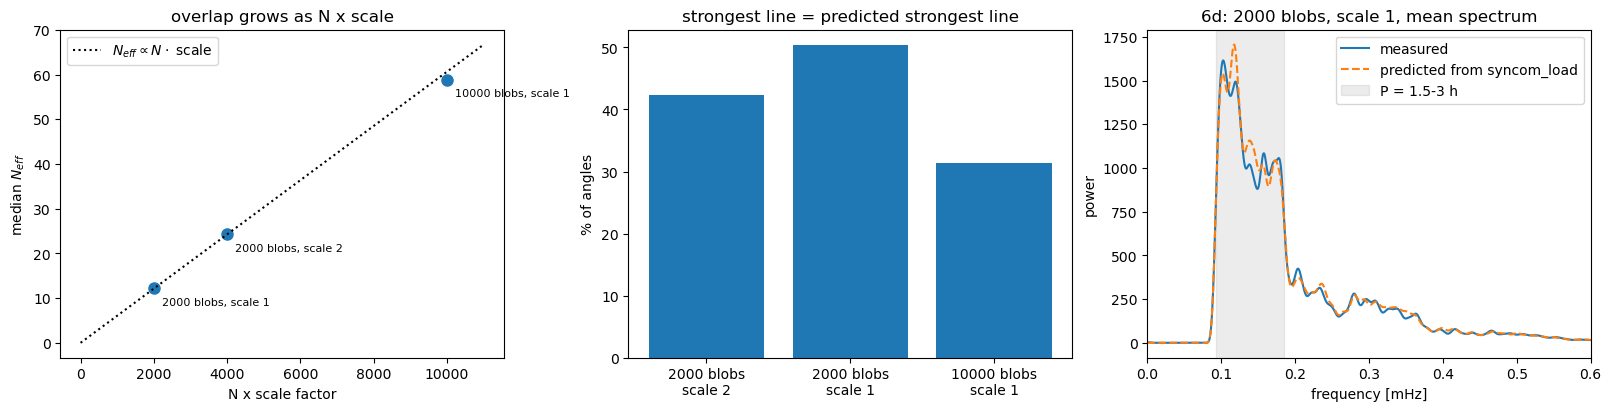

In [14]:
RUN_2000_S1 = "SynCOM_v3.1-periodic_blobs_N_BLOBS_2000_SCALE_FACTOR_1.0"
params_s1, scale_s1, blobs_s1, lc_s1 = load_run(RUN_2000_S1, 2000, 1.0, 500)
gx_s1 = angular_profiles(params_s1, blobs_s1)
rep_s1 = frequency_report(blobs_s1, gx_s1, lc_s1)

runs = {"2000 blobs, scale 2 (6b)": (rep_20, 2000 * 2.0),
        "2000 blobs, scale 1 (6d)": (rep_s1, 2000 * 1.0),
        "10000 blobs, scale 1 (6c)": (rep_31, 10000 * 1.0)}
print(f"{'':52s}" + "".join(f"{name:>28s}" for name in runs))
for name, fmt in rows + [("N x scale", None)]:
    if fmt is None:
        print(f"{name:52s}" + "".join(f"{n_s:>28.0f}" for _, n_s in runs.values()))
    else:
        print(f"{name:52s}" + "".join(f"{fmt(r):>28s}" for r, _ in runs.values()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
n_scale = np.array([n_s for _, n_s in runs.values()])
n_eff_median = np.array([np.median(r["n_eff"]) for r, _ in runs.values()])
ax[0].plot(n_scale, n_eff_median, "o", ms=8)
for (name, _), x, y in zip(runs.items(), n_scale, n_eff_median):
    ax[0].annotate(name.split(" (")[0], (x, y), textcoords="offset points", xytext=(6, -12), fontsize=8)
x = np.linspace(0, 11000, 2)
ax[0].plot(x, x * n_eff_median[0] / n_scale[0], "k:", label=r"$N_{eff} \propto N \cdot$ scale")
ax[0].set(xlabel="N x scale factor", ylabel=r"median $N_{eff}$", title="overlap grows as N x scale")
ax[0].legend()
ax[1].bar(range(3), [100 * r["agree"] for r, _ in runs.values()], tick_label=[name.split(" (")[0].replace(", ", "\n") for name in runs])
ax[1].set(ylabel="% of angles", title="strongest line = predicted strongest line")
mhz = freq / CADENCE * 1e3
ax[2].plot(mhz, rep_s1["measured"], label="measured")
ax[2].plot(mhz, rep_s1["predicted"], "--", label="predicted from syncom_load")
ax[2].axvspan(1 / 36 / CADENCE * 1e3, 1 / 18 / CADENCE * 1e3, color="gray", alpha=0.15, label="P = 1.5-3 h")
ax[2].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power", title="6d: 2000 blobs, scale 1, mean spectrum")
ax[2].legend()
plt.show()

assert abs(np.median(rep_s1["n_eff"]) / np.median(rep_20["n_eff"]) - 0.5) < 0.05    # half the overlap of 6b
assert rep_s1["agree"] > rep_20["agree"]                                            # periods easier to read per angle
assert rep_s1["corr"] > 0.98 and abs(rep_s1["power_ratio"] - 1) < 0.10
assert abs(rep_s1["best_scale"] - 1) <= 0.01

**Observed.** The cube `SynCOM_v3.1-periodic_blobs_N_BLOBS_2000_SCALE_FACTOR_1.0` (3600 × 659 × 500) was read from disk; its light curves match the model to $3 \times 10^{-15}$.

| | 2000 blobs, scale 2 (6b) | **2000 blobs, scale 1 (6d)** | 10000 blobs, scale 1 (6c) |
|---|---|---|---|
| $N \cdot \text{scale}$ | 4000 | **2000** | 10000 |
| effective number of blobs per angle $N_\text{eff}$ (median) | 24.3 | **12.2** | 58.9 |
| blobs making ≥ 95% of the light at their own angle | 0 | 0 | 0 |
| angles whose strongest line is the predicted strongest line | 42% | **50%** | 31% |
| mean spectrum: correlation with the `syncom_load` prediction | 0.9935 | **0.9956** | 0.9933 |
| mean spectrum: measured / predicted power | 0.931 | 0.976 | 1.007 |
| best period scale | 1.000 | **1.000** | 1.005 |

- **Overlap follows $N \cdot \text{scale}$.** Halving the scale halved $N_\text{eff}$ exactly (12.2 / 24.3 = 0.50). The three runs lie on one line through the origin: the 6b value predicts 12.2 and 60.8, and 12.2 and 58.9 are measured.
- **One period per angle gets easier, slowly.** The strongest line is the predicted one at 50% of the angles, up from 42%. The improvement comes from the smaller overlap, not from the longer record: the first 300 frames of this run alone give 52%. About 12 blobs still share each angle, so no blob dominates its own light curve.
- **The population of periods is the `syncom_load` one**, with the best match of the three runs (correlation 0.9956, best period scale exactly 1.000, power within 2.4%).

**Conclusion of 6b–6d.** The frequencies in the images are always the `syncom_load` ones. How well one period per position angle can be read depends only on the overlap, $N_\text{eff} \propto N \cdot \text{scale}$: 12 overlapping blobs give 50%, 24 give 42%, 59 give 31%. Reading the period of every angle needs $N_\text{eff} \approx 1$, i.e. $N \cdot \text{scale}$ of order 100–200 (for example 200 blobs at scale 0.5–1), or a period profile that varies smoothly with angle. ✅

### 6e. The period range without knowing the answer

**Question.** Sections 6a–6d check the images *against* `syncom_load`: they use the input periods (and speeds and sizes) to predict what the spectrum should be. Could the range of periods be measured from the images alone, as it would have to be for real observations?

**Physics: why the period range leaves sharp edges in the spectrum.** Every blob adds lines at $f = n/P$ (section 6). The fundamentals ($n = 1$) of all blobs fill the band $[1/P_\text{max},\ 1/P_\text{min}]$, and they carry most of the power (82% in 6b). So the mean spectrum over all angles has
- **a lower edge** at $f = 1/P_\text{max}$: no blob has a longer period, so below it there are no lines at all, only the leakage of the window. The power falls to half of its peak there.
- **an upper edge** at $f = 1/P_\text{min}$: above it there are only harmonics ($n \ge 2$), weaker by $e^{-2\pi^2 n^2 \sigma_t^2/P^2}$. The power drops steeply there.

The edges are blurred by the frequency resolution of the record (about $2/T$ for a Hann window), so a longer record locates them more precisely.

**The blind estimate** (`blind_period_range`) uses only the light curves. It doesn't know the periods, the speeds, the sizes or the number of blobs:
1. the mean Fourier power spectrum over all position angles
2. its highest point $f_\text{peak}$
3. the longest period: the first frequency below $f_\text{peak}$ where the power drops under half the peak
4. the shortest period: the steepest fall of the (smoothed) log-power above $f_\text{peak}$

**Expected.** For the three runs of 6b–6d, the blind range agrees with the `syncom_load` range (18–36 frames, 1.5–3 h) to within 5%. The comparison is a separate step after the estimate, and the estimate never sees the answer.

**Limits.** This works because the `syncom_load` periods fill a flat band with sharp edges. A smooth or peaked distribution of periods has no edges: then a dominant period and a spread are the measurable quantities. The range also says nothing about *which* angle has which period (see 6b–6d).


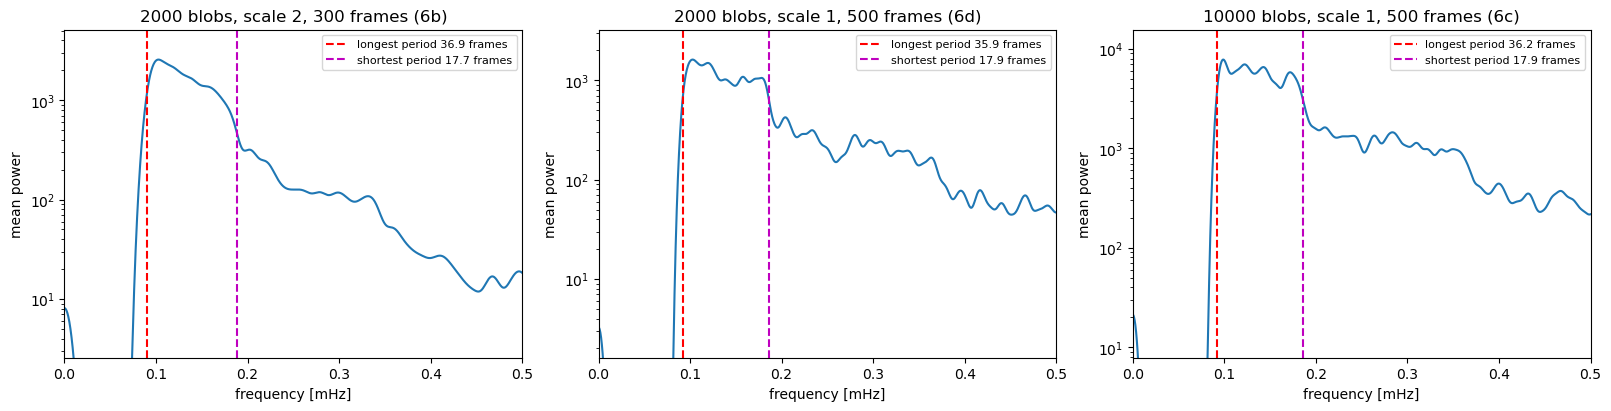

run                                        blind estimate [frames]    blind estimate [h]
2000 blobs, scale 2, 300 frames (6b)            17.7 - 36.9             1.48 - 3.08     
2000 blobs, scale 1, 500 frames (6d)            17.9 - 35.9             1.49 - 2.99     
10000 blobs, scale 1, 500 frames (6c)           17.9 - 36.2             1.49 - 3.02     
2000 blobs, scale 2, 300 frames (6b)     syncom_load: 18.0 - 36.0 frames; blind error -1.6% / +2.5%
2000 blobs, scale 1, 500 frames (6d)     syncom_load: 18.0 - 36.0 frames; blind error -0.7% / -0.2%
10000 blobs, scale 1, 500 frames (6c)    syncom_load: 18.0 - 36.0 frames; blind error -0.7% / +0.7%


In [15]:
def blind_period_range(light_curves, smooth=9, search=0.15):
    """
    Longest and shortest period [frames] of a run, from its light curves alone.

    light_curves: [time, angle] brightness at one radius (any number of angles).
    Uses nothing else: no periods, speeds, sizes or number of blobs.
    """
    n_t = light_curves.shape[0]
    window = np.hanning(n_t)
    series = light_curves - light_curves.mean(axis=0)                     # remove each angle's mean
    power = (np.abs(np.fft.rfft(series * window[:, None], n=NFFT, axis=0)) ** 2).mean(axis=1)

    k_peak = np.argmax(power)                                             # strongest frequency

    # lower edge = longest period: first frequency below the peak where the power is under half the peak
    k_low = k_peak - np.argmax(power[k_peak::-1] < power[k_peak] / 2)

    # upper edge = shortest period: steepest fall of the smoothed log-power above the peak
    log_power = np.convolve(np.log(power + 1e-300), np.ones(smooth) / smooth, mode="same")
    k_search = k_peak + int(search * NFFT)                                 # look up to 0.15 cycles/frame above the peak
    k_high = k_peak + np.argmin(np.diff(log_power)[k_peak:k_search])

    return 1 / freq[k_low], 1 / freq[k_high], power, (k_low, k_peak, k_high)


blind_runs = {"2000 blobs, scale 2, 300 frames (6b)": lc,
              "2000 blobs, scale 1, 500 frames (6d)": lc_s1,
              "10000 blobs, scale 1, 500 frames (6c)": lc_31}
blind = {name: blind_period_range(curves) for name, curves in blind_runs.items()}

fig, ax = plt.subplots(1, 3, figsize=(16, 4), layout="constrained", sharey=False)
mhz = freq / CADENCE * 1e3
for a, (name, (p_long, p_short, power, (k_low, k_peak, k_high))) in zip(ax, blind.items()):
    a.semilogy(mhz, power)
    a.axvline(mhz[k_low], c="r", ls="--", label=f"longest period {p_long:.1f} frames")
    a.axvline(mhz[k_high], c="m", ls="--", label=f"shortest period {p_short:.1f} frames")
    a.set(xlim=(0, 0.5), ylim=(power[k_peak] * 1e-3, power[k_peak] * 2), xlabel="frequency [mHz]",
          ylabel="mean power", title=name)
    a.legend(fontsize=8)
plt.show()

print(f"{'run':40s}{'blind estimate [frames]':>26s}{'blind estimate [h]':>22s}")
for name, (p_long, p_short, *_) in blind.items():
    print(f"{name:40s}{p_short:>12.1f} - {p_long:<11.1f}{p_short * CADENCE / 3600:>10.2f} - {p_long * CADENCE / 3600:<9.2f}")

# Only now compare with the answer: the period range put in by syncom_load
for name, (p_long, p_short, *_), run_blobs in zip(blind, blind.values(), (blobs, blobs_s1, blobs_31)):
    true_long, true_short = run_blobs["period"].max(), run_blobs["period"].min()
    print(f"{name:40s} syncom_load: {true_short:.1f} - {true_long:.1f} frames; "
          f"blind error {100 * (p_short / true_short - 1):+.1f}% / {100 * (p_long / true_long - 1):+.1f}%")
    assert abs(p_long / true_long - 1) < 0.05 and abs(p_short / true_short - 1) < 0.05

**Observed.** | run | blind estimate | `syncom_load` | error (shortest / longest) |
|---|---|---|---|
| 2000 blobs, scale 2, 300 frames | 17.7–36.9 frames (1.48–3.08 h) | 18.0–36.0 frames (1.5–3 h) | −1.6% / +2.5% |
| 2000 blobs, scale 1, 500 frames | 17.9–35.9 frames (1.49–2.99 h) | 18.0–36.0 frames | −0.7% / −0.2% |
| 10000 blobs, scale 1, 500 frames | 17.9–36.2 frames (1.49–3.02 h) | 18.0–36.0 frames | −0.7% / +0.7% |

- **The range is recovered without the answer**, to within 2.5% in every run. `blind_period_range` only sees the light curves.
- **Both edges are clear in the spectra:** a cliff of more than two orders of magnitude below $1/P_\text{max}$, where there are no lines, and a step down at $1/P_\text{min}$, where only harmonics remain.
- **The 500-frame runs are more accurate** (0.2–0.7%) than the 300-frame run (1.6–2.5%), as expected from the finer frequency resolution $1/T$.
- **What it doesn't give:** which angle has which period. It also relies on the flat, sharp-edged period distribution of `syncom_load`. ✅

## 7. The 30-frame FITS sample

**Change.** `syncom_core` no longer writes a FITS file for every frame. `write_fits_frames` writes only the requested frames. The main notebook wrote time steps 0–29 of its `v3.1-periodic_blobs` run (10000 blobs, scale factor 1, 300 s cadence). The repository keeps them in `sample_FITS/`.

**Physics.** 30 frames = 2.5 h. Blobs with $P \le 30$ frames (2.5 h) reappear inside the sample. That's about 2/3 of them, since $P$ is 18–36 frames.

**Expected.**
- Each of the 30 files is float64, shape (NY, NX) = (659, 3600), with its time step in the header.
- They are **identical** to a fresh computation with `syncom_image`, since the model is deterministic and the files are not compressed.


✅ Built cube (3600, 659, 30) from 30 FITS files in /Users/valmirmoraesfilho/Downloads/SynCOM-python-main/SynCOM_python/SynCOM_runs/SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0/FITS
{'BITPIX': -64, 'NAXIS1': 3600, 'NAXIS2': 659, 'TSTEP': 7, 'TIME': 2100.0, 'CADENCE': 300.0, 'PIXEL': 0.0141875720451562, 'NBLOBS': 10000}
largest difference between the FITS sample and a fresh computation: 0.0e+00


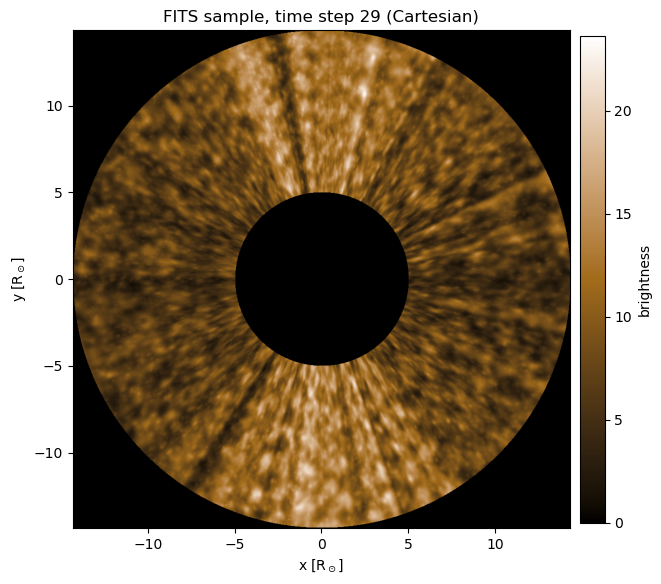

In [16]:
# The sample of the main notebook's run (6c): in the repository, or in the run folder after running it
fits_dir = Path("sample_FITS") / RUN_31
if not fits_dir.exists():
    fits_dir = syncom_run_dir(RUN_31, "fits")
sample = load_fits_cube(fits_dir, RUN_31, 0, 30, NX, NY)            # [NX, NY, 30]
assert sample is not None, "sample_FITS/ not found: run SynCOM_python_notebook.ipynb first (it writes the sample)"

header = fits.getheader(fits_dir / f"{RUN_31}_0007.fts")
print({k: header[k] for k in ("BITPIX", "NAXIS1", "NAXIS2", "TSTEP", "TIME", "CADENCE", "PIXEL", "NBLOBS")})

fresh = np.stack([syncom_image(params_31, blobs_31, t, gx=gx_31) for t in range(30)], axis=2)   # same run, recomputed
max_diff = np.abs(sample - fresh).max()
print(f"largest difference between the FITS sample and a fresh computation: {max_diff:.1e}")
assert header["BITPIX"] == -64 and (header["NAXIS1"], header["NAXIS2"]) == (NX, NY) and header["TSTEP"] == 7
assert header["NBLOBS"] == params_31["syncom_n_blobs"]
assert max_diff < 1e-12

plot_rect_image(polar_to_rect(sample[:, :, 29], POLAR_PHI_RANGE, POLAR_RHO_RANGE, n=1024),
                title="FITS sample, time step 29 (Cartesian)", cmap=cmap_punch, label="brightness")

**Observed.** - The 30 files of `sample_FITS/SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0/` load into a `(3600, 659, 30)` cube.
- Each file is float64 (`BITPIX = -64`), 3600 × 659. The header of time step 7 has `TSTEP = 7`, `TIME = 2100 s`, the cadence, the pixel size and `NBLOBS = 10000`.
- The largest difference from a fresh computation of the same run is **0.0**: the files are bit-identical to the model.
- The Cartesian view of time step 29 is filled evenly from 5 R☉ to 14.3 R☉, with no dim ring at the occulter. ✅

## 8. Storage (for reference; no compression is applied)

FITS frames and cubes are written as uncompressed float64, the most conservative choice: no information is lost and every FITS reader can open them. The cell below measures, in memory, what **lossless** options would save on one frame, for a future decision. Nothing is written to disk.


In [17]:
import io

def size_mb(hdul):
    buffer = io.BytesIO(); hdul.writeto(buffer); return len(buffer.getvalue()) / 1e6, buffer

frame = fresh[:, :, 0].T                                                   # (NY, NX) float64
raw, _ = size_mb(fits.HDUList([fits.PrimaryHDU(frame)]))
gz, buffer = size_mb(fits.HDUList([fits.PrimaryHDU(), fits.CompImageHDU(frame, compression_type="GZIP_2", quantize_level=0.0)]))
buffer.seek(0)
identical = np.array_equal(fits.open(buffer)[1].data, frame)

print(f"float64, uncompressed (used):      {raw:6.2f} MB per frame, {raw * 300 / 1000:5.2f} GB for 300 frames")
print(f"float64, GZIP_2 lossless (not used): {gz:6.2f} MB per frame ({100 * (1 - gz / raw):.0f}% smaller), bit-identical: {identical}")
assert identical

float64, uncompressed (used):       18.98 MB per frame,  5.69 GB for 300 frames
float64, GZIP_2 lossless (not used):  15.49 MB per frame (18% smaller), bit-identical: True


**Observed.** - Uncompressed float64: 18.98 MB per frame, 5.69 GB for 300 frames.
- Lossless GZIP_2 would save 18% (15.49 MB per frame for this 10000-blob frame) and read back bit-identical.
- As requested, no compression is applied. This is recorded here for a future decision.

## 9. Planets in the frames (v4-planet_body)

**Change.** `syncom_planets.py` adds planets to the frames. The switch is `default_syncom_prams(SYNCOM_PLANETS=("mercury", "jupiter"), SYNCOM_START_TIME=...)`; with `SYNCOM_PLANETS=()` (the default) nothing changes. The planet database `PLANET_DB` has Mercury to Neptune:
- **Confirmed** against the PUNCH frames: Mercury, Venus, Mars, Jupiter (sections 9a–9d).
- **Ephemeris only**: Saturn, Uranus, Neptune. They were outside the PUNCH field in these frames (elongation 51–119°) and are drawn with the same calibration.

A planet that stays outside the frame for the whole run is not modelled. `syncom_load` imports the module, and `syncom_core`:
1. builds each planet's track once (`syncom_planet_table`);
2. measures the local fluctuation of the first blob-only frame at each planet's radius (`planet_sigmas`);
3. adds the planets to every frame (`add_planets`).

The run is that of the main notebook: NY = 7779, pixel 0.0225 R☉ (5–180 R☉), 1000 blobs, scale 1, 300 s cadence, time step 0 = **2026-07-26 06:40 UTC**.

**Physics.**
- **Two kinds of information.** What depends on the planet and the day comes from the **ephemeris**, at every time step: position, motion, distances, phase angle and V magnitude. How PUNCH shows a point source of a given magnitude is a property of the **instrument**, measured once on PUNCH L3 CAM frames (`PUNCH_CAL`, `calibrate_punch`).
- **Where.** As in `movie_generic.ipynb` (PUNCH explore), the geocentric astrometric direction comes from astropy (`body_direction`: barycentric positions, light-time iteration, no aberration, the convention of the star-fitted RA/Dec WCS of PUNCH L3).
  - Elongation $\varepsilon$ is the angle to the Sun's centre.
  - Position angle $\psi$ is measured from solar north, counterclockwise through east.
  - The radius in solar radii is $r = \varepsilon/\theta_\odot$, with $\theta_\odot = \arcsin(R_\odot/d_\odot)$ (`RSUN_ARC`). PUNCH mosaics use the zenithal equidistant (ARC) projection around the Sun, so $r$ is linear in $\varepsilon$, as on the PUNCH elongation grid and in the SynCOM polar frame.
- **Polar coordinates.** A SynCOM column is an angle $\phi$ with $x = r\cos\phi$, $y = -r\sin\phi$ in `polar_to_rect`. The PUNCH view (solar north up, east left) needs $\phi = 270^\circ - \psi$. PUNCH frames are unwrapped onto the same grid through $\text{lat} = \arcsin(\sin\varepsilon\cos\psi)$, $\text{lon} = \operatorname{atan2}(-\sin\varepsilon\sin\psi, \cos\varepsilon)$ and the primary WCS.
- **Brightness.** The V magnitudes follow Mallama & Hilton (2018), from the heliocentric and geocentric distances and the phase angle (and, for Saturn and Uranus, the latitude of the Earth seen from the planet: Saturn's ring tilt). A detector is linear only up to saturation: the unsaturated profile is $A\,P(x)$ with $A = A_0\,10^{-0.4(V-V_0)}$, $(A_0, V_0)$ from an unsaturated planet and $P$ of peak 1. At the full well $S$ the recorded profile is clipped, $\min(A\,P(x), S)$: the core becomes **flat and wider the more the planet is overexposed**, $D_{1/2} = 2\,r$ where $A\,P(r) = S/2$, and the excess charge also runs into **bleed streaks**. What makes a planet look realistic is its contrast against the local fluctuation, $S/N = A/\sigma$. $\sigma$ is the 5σ-clipped standard deviation of the frame minus its 2° running median along position angle, measured the same way on PUNCH and SynCOM frames.
- **Size.** The disks (Mercury 5–10″, Mars 4–25″, Jupiter 30–45″, Venus 10–60″) are not larger than a PUNCH pixel (81″), so the apparent size is the instrument's response (a core plus a faint halo, slightly wider toward the outer field) clipped at saturation. It is measured as the equivalent diameter $2\sqrt{A/\pi}$ of the area above half the peak and above 30σ. A sky angle $s$ spans $s/\theta_\odot$ R☉ radially and $s/\sin\varepsilon$ radians in position angle.
- **Motion.** Planets move by $\lesssim 1\,R_\odot$ per 8 h in elongation. Mercury's sidereal period is 87.969 d.

**Expected.**
1. The four planet markers of the PUNCH PNG (2026-07-18 11:28), the `movie_generic` positions and the planets seen in the FITS data are the same sources, within 1 PNG pixel. In both files every planet's half-maximum centroid is within 2.5 PUNCH px of the ephemeris position.
2. The header-free ephemeris (`planet_ephemeris`) agrees with the header path (`planet_pixel_punch`) to ≤ 0.01° in $\varepsilon$ and ≤ 0.05° in $\psi$.
3. `calibrate_punch` reproduces the stored `PUNCH_CAL`. The model reproduces, for all seven planets seen in the two files, the S/N (within 0.75–1.33) and the visible size (30σ diameter within 0.75–1.33).
4. Venus and Mars in SynCOM, at the times of the two PUNCH frames: on the PUNCH position (within 2.5 PUNCH px), with the PUNCH S/N and visible size (within 0.75–1.33).
5. Mercury + Jupiter in SynCOM: each centre on its table, S/N as the table, moving at the ephemeris speed; Mercury + Jupiter = blobs + Mercury alone + Jupiter alone; with `SYNCOM_PLANETS=()` the frames are exactly the blob-only frames.
6. Ephemeris-only planets: magnitudes match their known values at opposition; a planet outside the frame for the whole run is not modelled.


In [2]:
import matplotlib.image as mpimg
from matplotlib.colors import to_rgb, LogNorm
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.time import Time, TimeDelta
from astropy.coordinates import get_body_barycentric
from syncom_core import syncom_core
from polar_to_rect import polar_to_rect
from syncom_planets import (PUNCH_CAL, PLANET_DB, planet_ephemeris, planet_pixel_punch, syncom_planet_table,
                            punch_snr_shape, unwrap_punch_polar, local_sigma, planet_rows, planet_sigmas,
                            calibrate_punch, column_to_solar_pa, _punch_sizes, _clipped_diameters)

PLANET_DIR = "/Users/valmirmoraesfilho/Downloads/Research/PUNCH/PUNCH_Flow_Tracking_and_Notebooks/Planets/"
F18 = PLANET_DIR + "PUNCH_L3_CAM_20260718112800_v0l --  position of planets.fits"
PNG18 = PLANET_DIR + "PUNCH_L3_CAM_20260718112800_v0l --  position of planets.png"
F26 = PLANET_DIR + "PUNCH_L3_CAM_20260726064000_v0l -- mercury more visible.fits"
COLORS = {"mercury": "lightskyblue", "venus": "royalblue", "mars": "red", "jupiter": "lime"}   # as in movie_generic

def planet_params(planets=("mercury", "jupiter"), start="2026-07-26T06:40:00"):
    # the main notebook's run (v4-planet_body)
    return default_syncom_prams(SYNCOM_NY=7779, SYNCOM_PIXEL=0.0225, SYNCOM_N_BLOBS=1000, SYNCOM_SCALE_FACTOR=1.0,
                                SYNCOM_PLANETS=planets, SYNCOM_START_TIME=start)

def centroid(d, x, y, H=10):
    # half-maximum centroid of a source near (x, y), FITS pixels
    xi, yi = int(round(x)), int(round(y)); c = d[yi - H:yi + H + 1, xi - H:xi + H + 1]; yy, xx = np.mgrid[-H:H + 1, -H:H + 1]
    w = np.clip(c - np.nanmedian(d[yi - 30:yi + 31, xi - 30:xi + 31]), 0, None); w = w * (w > 0.5 * np.nanmax(w))
    return (w * xx).sum() / w.sum() + xi, (w * yy).sum() / w.sum() + yi

def moment_centroid(m, c0, r0, hc=60, hr=160):
    # first moment (column, row) and peak of a planet-only polar image around (c0, r0)
    cs = np.arange(int(c0) - hc, int(c0) + hc + 1); rs = np.arange(max(int(r0) - hr, 0), int(r0) + hr + 1)
    z = m[np.ix_(cs % 3600, rs)]; w = np.clip(z, 0, None)
    return (w.sum(1) @ cs) / w.sum(), (w.sum(0) @ rs) / w.sum(), z.max()

def syncom_size(m, tr, sig, pixel=0.0225, level=30.0):
    # equivalent diameters [deg on the sky] above half the peak and above level x sigma, planet-only polar image
    c0, r0 = int(round(tr["col"][0])), int(round(tr["r_px"][0]))
    z = m[np.ix_(np.arange(c0 - 200, c0 + 201) % 3600, np.arange(max(r0 - 300, 0), min(r0 + 301, m.shape[1])))]
    k = np.unravel_index(np.argmax(z), z.shape)
    px = (pixel * tr["eps"][0] / tr["r"][0]) * (0.1 * np.sin(np.radians(tr["eps"][0])))     # one pixel [deg^2]
    def diam(mask):
        lab, _ = ndimage.label(mask); return 2 * np.sqrt((lab == lab[k]).sum() * px / np.pi)
    return diam(z > 0.5 * z[k]), diam(z > level * sig)

p_pl = planet_params()

No file or date entered. Using default: syncom_20140414_densfix.sav


### 9a. Locating the planets: PNG ↔ FITS ↔ ephemeris
The PNG was made by `movie_generic.ipynb`: a 10 × 10 inch figure at 100 dpi, axes filling it, axis limits = image + 6 % margin. So each planet's marker (its colour in `movie_generic`) maps to a FITS pixel. The cell compares each marker with the planet's half-maximum centroid in the FITS data and with the `movie_generic` position (WCS `key='A'`), then checks every planet of both files.

In [3]:
png = mpimg.imread(PNG18)[:, :, :3]
H, W = png.shape[:2]
hd18, d18 = fits.getheader(F18, 1), fits.getdata(F18, 1).astype(float)
hd26, d26 = fits.getheader(F26, 1), fits.getdata(F26, 1).astype(float)
nx18, ny18, M = hd18["NAXIS1"], hd18["NAXIS2"], 0.06
x0, x1, y0, y1 = -0.5 - M * nx18, nx18 - 0.5 + M * nx18, -0.5 - M * ny18, ny18 - 0.5 + M * ny18
png_to_fits = lambda c, r: (x0 + (c + 0.5) / W * (x1 - x0), y0 + (H - (r + 0.5)) / H * (y1 - y0))
scale = (x1 - x0) / W                                             # FITS px per PNG px

print("planet    PNG marker -> FITS     data centroid       movie_generic      data-PNG [PNG px]  data-ephemeris [FITS px]")
for name, colour in COLORS.items():
    ring = np.linalg.norm(png - np.array(to_rgb(colour)), axis=2) < 0.12
    ring[850:, :200] = False                                      # legend
    lab, n = ndimage.label(ring)
    rr, cc = np.nonzero(lab == np.argmax(ndimage.sum(ring, lab, range(1, n + 1))) + 1)
    xm, ym = png_to_fits(cc.mean(), rr.mean())
    loc = planet_pixel_punch(hd18, name); cx, cy = centroid(d18, loc["x"], loc["y"])
    d_png, d_eph = np.hypot(cx - xm, cy - ym) / scale, np.hypot(cx - loc["x"], cy - loc["y"])
    print(f"{name:8s}  ({xm:7.1f}, {ym:7.1f})   ({cx:7.1f}, {cy:7.1f})   ({loc['x']:7.1f}, {loc['y']:7.1f})   {d_png:5.2f}              {d_eph:5.2f}")
    assert d_png < 1.0 and d_eph <= 2.5

loc26 = {n: planet_pixel_punch(hd26, n) for n in ("mercury", "venus", "mars")}
for n, loc in loc26.items():
    cx, cy = centroid(d26, loc["x"], loc["y"])
    print(f"07-26 {n:8s} r = {loc['r']:6.1f} Rsun, PA = {loc['pa']:5.1f} deg: centroid {np.hypot(cx - loc['x'], cy - loc['y']):.1f} FITS px from the ephemeris")
    assert np.hypot(cx - loc["x"], cy - loc["y"]) <= 2.5
jl = planet_pixel_punch(hd26, "jupiter")
print(f"07-26 jupiter  r = {jl['r']:6.1f} Rsun: inside the area without data (CAM data start at ~20.6 Rsun)")

for hd in (hd18, hd26):
    for name in ("mercury", "jupiter"):
        loc = planet_pixel_punch(hd, name); e = planet_ephemeris(name, loc["time"])
        de, dp = abs(e["eps"][0] - loc["eps"]), abs((e["pa"][0] - loc["pa"] + 180) % 360 - 180)
        assert de <= 0.01 and dp <= 0.05, (name, de, dp)
print("header-free ephemeris = header path to <= 0.01 deg (elongation) and <= 0.05 deg (PA)")

planet    PNG marker -> FITS     data centroid       movie_generic      data-PNG [PNG px]  data-ephemeris [FITS px]
mercury   ( 2433.9,  1866.8)   ( 2431.6,  1868.4)   ( 2432.1,  1868.8)    0.59               0.66
venus     (  109.3,  1903.0)   (  105.9,  1905.5)   (  105.9,  1905.4)    0.91               0.05
mars      ( 3907.7,  2224.1)   ( 3905.9,  2225.3)   ( 3907.3,  2224.8)    0.47               1.42
jupiter   ( 1687.4,  2031.4)   ( 1684.8,  2032.5)   ( 1686.8,  2032.3)    0.62               2.10
07-26 mercury  r =   65.2 Rsun, PA = 262.7 deg: centroid 0.3 FITS px from the ephemeris
07-26 venus    r =  170.5 Rsun, PA =  94.3 deg: centroid 1.2 FITS px from the ephemeris
07-26 mars     r =  168.2 Rsun, PA = 275.0 deg: centroid 2.0 FITS px from the ephemeris
07-26 jupiter  r =    9.2 Rsun: inside the area without data (CAM data start at ~20.6 Rsun)
header-free ephemeris = header path to <= 0.01 deg (elongation) and <= 0.05 deg (PA)


keyword looks very much like CROTAn but isn't. [astropy.wcs.wcs]


### 9b. The PUNCH calibration: brightness, saturation and size
`calibrate_punch` measures every planet that has data in the two files. The zero point and the unsaturated shape come from the unsaturated Mercury of 07-18. A planet whose peak is more than 2× below its linear prediction is saturated, and the S/N of the saturated planets gives the ceiling against radius. The growth of the core toward the outer field is fitted to the measured sizes. The model is `min(linear S/N × shape, ceiling)`.

/Users/valmirmoraesfilho/Downloads/SynCOM-python-main/SynCOM_python/syncom_planets.py:462: RuntimeWarning: All-NaN slice encountered
  hp = x - np.nanmedian(win, axis=-1)


zero point: mercury 2026-07-18T11:28  peak 3.696e-12 MSB at V 3.83
unsaturated shape: core 0.0859 deg, halo 0.2773 deg at 2.0%;  core growth 0.00278 per Rsun beyond 36.4 Rsun
size model rms error 29% (log)
date        planet    r [Rsun]  V      over   S/N meas/model    half-max diam meas/model [deg]  30-sigma diam meas/model [deg]  fit offset
2026-07-18  mercury    36.4  +3.83     1.0     547 /    541    0.092 / 0.087                 0.193 / 0.184                 0.71 px
2026-07-18  venus     167.0  -4.18   150.5    5700 /   5700    0.223 / 0.441                 1.064 / 0.835                 2.06 px
2026-07-18  mars      160.4  +1.31     1.0    6021 /   5480    0.129 / 0.126                 0.354 / 0.400                 1.38 px
2026-07-18  jupiter    30.9  -1.79    36.9    2182 /   2182    0.313 / 0.252                 0.720 / 0.663                 4.69 px
2026-07-26  mercury    65.2  +1.34     3.8    2331 /   2331    0.116 / 0.156                 0.457 / 0.421                 0.57 px


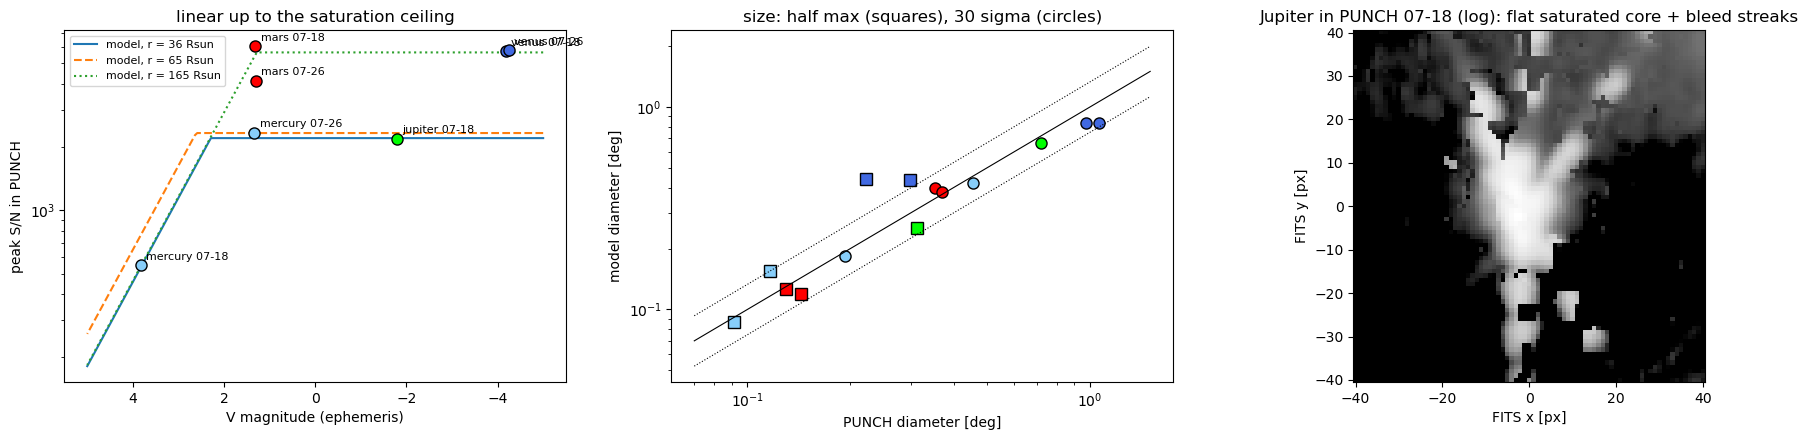

In [4]:
cal, sources, profile = calibrate_punch([F18, F26], p_pl)
for key in ("zp_peak", "zp_vmag", "sigma", "sat_r", "sat_snr", "psf_unsat", "psf_growth", "psf_r0"):
    assert np.allclose(cal[key], PUNCH_CAL[key], rtol=1e-6), key
print("\nstored PUNCH_CAL = measurement")
for s in sources:
    assert 0.75 < s["model_snr"] / s["snr"] < 1.33 and 0.75 < s["model_d_30"] / s["d_30"] < 1.33, s["planet"]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
V = np.linspace(-5, 5, 200)
for r_, ls in ((36, "-"), (65, "--"), (165, ":")):
    lin, ceil, *_ = punch_snr_shape(V, np.full_like(V, r_))
    ax[0].semilogy(V, np.minimum(lin, ceil), ls, label=f"model, r = {r_} Rsun")
for s in sources:
    ax[0].semilogy(s["vmag"], s["snr"], "o", color=COLORS[s["planet"]], mec="k", ms=8)
    ax[0].annotate(f"{s['planet']} {s['time'][5:10]}", (s["vmag"], s["snr"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[0].invert_xaxis(); ax[0].set(xlabel="V magnitude (ephemeris)", ylabel="peak S/N in PUNCH", title="linear up to the saturation ceiling"); ax[0].legend(fontsize=8)
for s in sources:
    for key, mk_ in (("d_half", "s"), ("d_30", "o")):
        ax[1].loglog(s[key], s["model_" + key], mk_, color=COLORS[s["planet"]], mec="k", ms=8)
lim = [0.07, 1.5]; ax[1].plot(lim, lim, "k-", lw=0.8); ax[1].plot(lim, [l * 1.33 for l in lim], "k:", lw=0.8); ax[1].plot(lim, [l * 0.75 for l in lim], "k:", lw=0.8)
ax[1].set(xlabel="PUNCH diameter [deg]", ylabel="model diameter [deg]", title="size: half max (squares), 30 sigma (circles)")
loc = planet_pixel_punch(hd18, "jupiter"); xi, yi = int(round(loc["x"])), int(round(loc["y"]))
cut = d18[yi - 40:yi + 41, xi - 40:xi + 41]; bk = np.nanmedian(cut)
ax[2].imshow(np.clip(cut - bk, 1e-14, None), origin="lower", cmap="gray", norm=LogNorm(1e-14, np.nanmax(cut - bk)), extent=[-40.5, 40.5, -40.5, 40.5])
ax[2].set(title="Jupiter in PUNCH 07-18 (log): flat saturated core + bleed streaks", xlabel="FITS x [px]", ylabel="FITS y [px]")
plt.tight_layout(); plt.show()

### 9c. Venus and Mars: SynCOM against the PUNCH frames
SynCOM is run at the times of the two PUNCH frames, with Venus and Mars. For each planet the cell compares:
- the planet's position in the unwrapped PUNCH frame with its SynCOM track;
- the S/N;
- the visible size (30σ diameter);
- the two images, on the same stretch.

No file or date entered. Using default: syncom_20140414_densfix.sav
No file or date entered. Using default: syncom_20140414_densfix.sav
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 3.952726125717163 seconds
  Venus: r 167.00 -> 167.00 Rsun, PA 94.17 -> 94.17 deg, dr/dt 0.000 px/frame (0.0 km/s), V -4.18, S/N 5699 (saturated), in view 1/1 frames
  Mars: r 160.39 -> 160.39 Rsun, PA 275.46 -> 275.46 deg, dr/dt 0.000 px/frame (0.0 km/s), V +1.31, S/N 5480 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 3.990144968032837 seconds


venus  2026-07-18: r  167.0 Rsun, PA  94.2, V -4.18;  PUNCH - table: -0.41 col, +0.2 rows (tolerance 0.8, 9.5);  S/N PUNCH 5677, SynCOM 5699;  30-sigma diameter PUNCH 1.061, SynCOM 0.840 deg


mars   2026-07-18: r  160.4 Rsun, PA 275.5, V +1.31;  PUNCH - table: -0.16 col, -5.6 rows (tolerance 0.8, 9.5);  S/N PUNCH 6021, SynCOM 5025;  30-sigma diameter PUNCH 0.354, SynCOM 0.406 deg
No file or date entered. Using default: syncom_20140414_densfix.sav
No file or date entered. Using default: syncom_20140414_densfix.sav
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 3.857228994369507 seconds
  Venus: r 170.48 -> 170.48 Rsun, PA 94.31 -> 94.31 deg, dr/dt 0.000 px/frame (0.0 km/s), V -4.24, S/N 5760 (saturated), in view 1/1 frames
  Mars: r 168.24 -> 168.24 Rsun, PA 274.96 -> 274.96 deg, dr/dt 0.000 px/frame (0.0 km/s), V +1.31, S/N 5049, in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.000715017318726 seconds


venus  2026-07-26: r  170.5 Rsun, PA  94.3, V -4.24;  PUNCH - table: -0.56 col, +0.3 rows (tolerance 0.8, 9.5);  S/N PUNCH 5761, SynCOM 5760;  30-sigma diameter PUNCH 0.972, SynCOM 0.837 deg


mars   2026-07-26: r  168.2 Rsun, PA 275.0, V +1.31;  PUNCH - table: +0.54 col, -4.8 rows (tolerance 0.8, 9.5);  S/N PUNCH 4124, SynCOM 4215;  30-sigma diameter PUNCH 0.371, SynCOM 0.394 deg


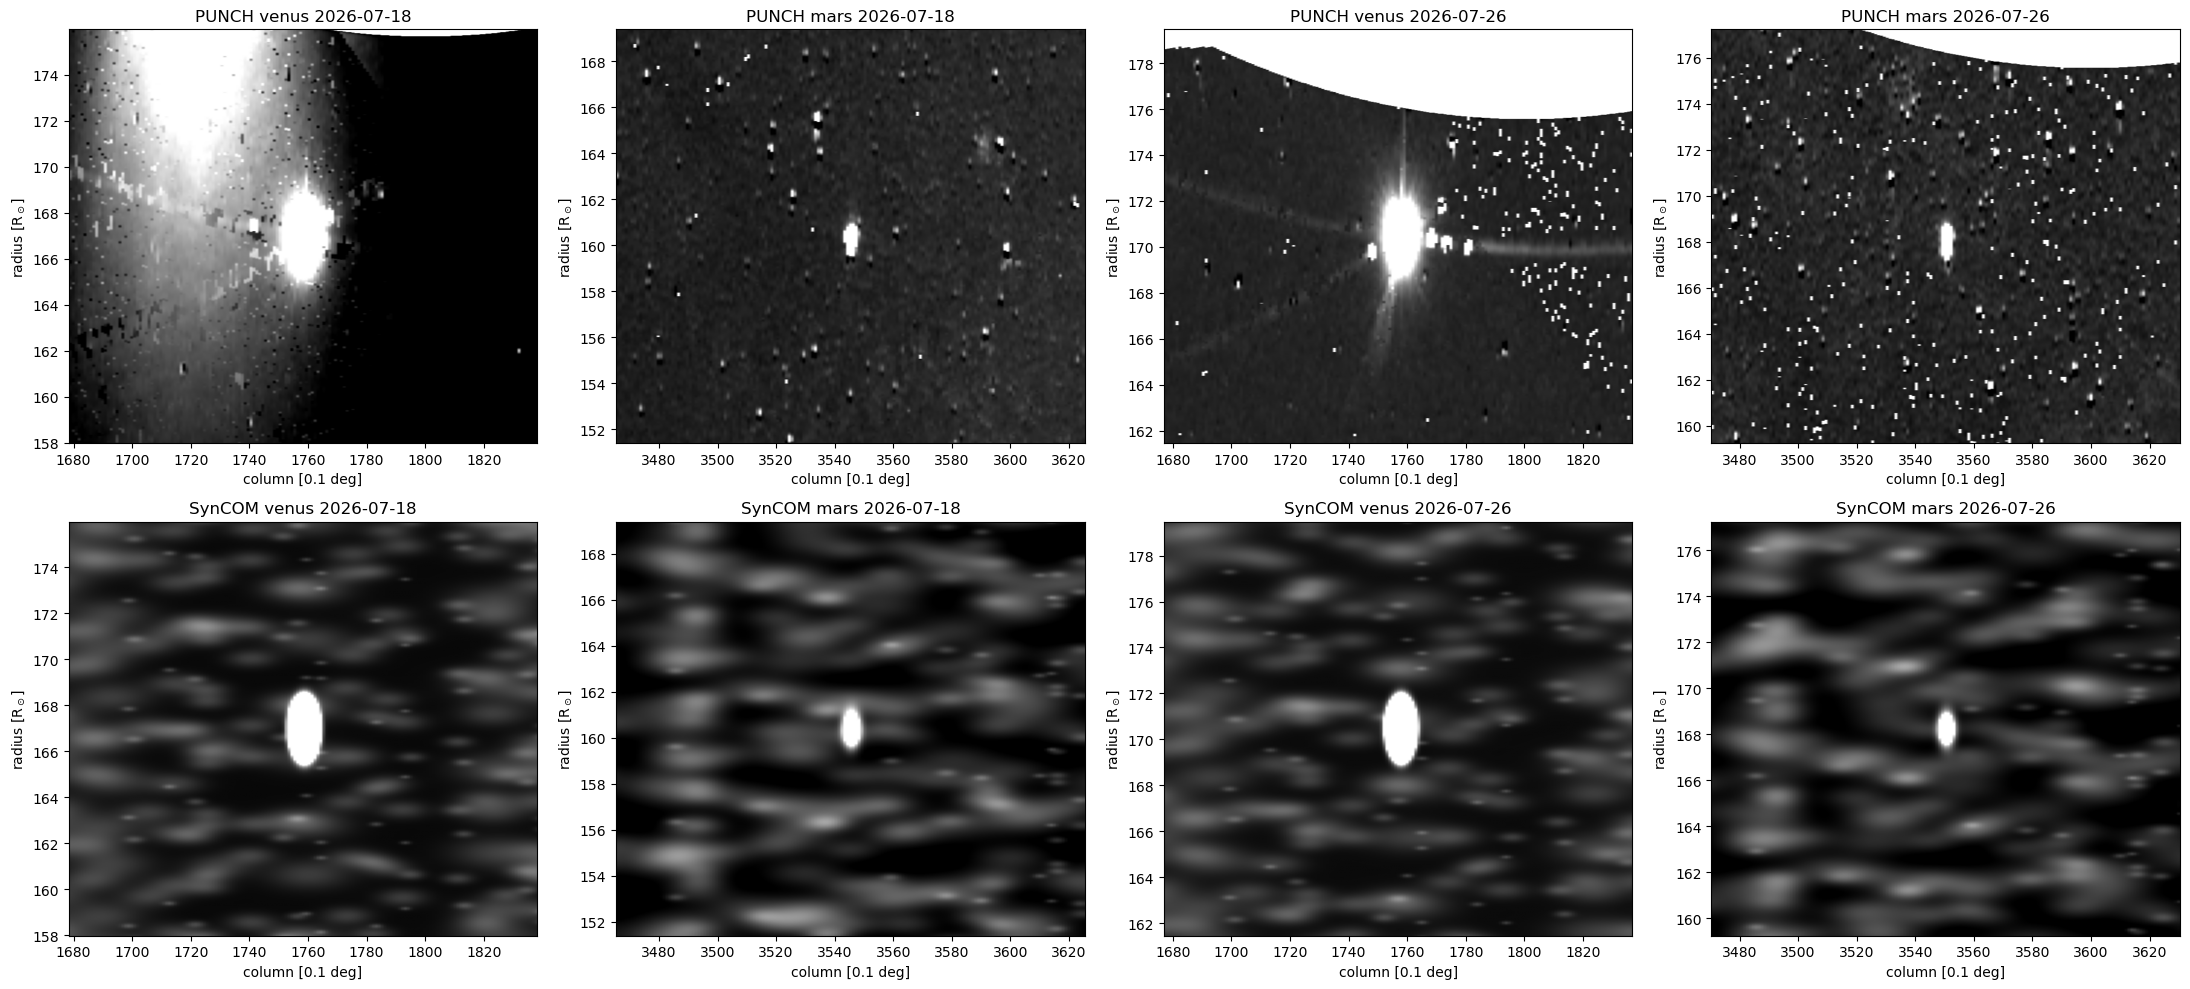

In [5]:
panels = []
for start, fpath, hd, d in (("2026-07-18T11:28:00", F18, hd18, d18), ("2026-07-26T06:40:00", F26, hd26, d26)):
    p_on = planet_params(("venus", "mars"), start)
    tab_vm = syncom_planet_table(p_on, 0, 1)
    c_off1 = syncom_core(1000, 0, 1, scale_factor=1.0, simple=True, params=planet_params((), start))[:, :, 0]
    c_on1 = syncom_core(1000, 0, 1, scale_factor=1.0, simple=True, params=p_on)[:, :, 0]
    sig_s = planet_sigmas(c_off1, tab_vm)
    for name, tr in tab_vm.items():
        c0, r0 = tr["col"][0], tr["r_px"][0]
        rows = np.arange(int(r0) - 400, int(r0) + 401)
        pol, _ = unwrap_punch_polar(fpath, p_on, rows=rows)
        full = np.full((3600, 7779), np.nan); full[:, rows] = pol
        z = full[np.ix_(np.arange(int(c0) - 15, int(c0) + 16), np.arange(int(r0) - 40, int(r0) + 41))]
        z = np.where(np.isfinite(z), z - np.nanmedian(z), 0); w = z * (z > 0.5 * z.max())
        pc, prow = (w.sum(1) @ np.arange(int(c0) - 15, int(c0) + 16)) / w.sum(), (w.sum(0) @ np.arange(int(r0) - 40, int(r0) + 41)) / w.sum()
        sig_p = local_sigma(pol, np.arange(380, 421))
        loc = planet_pixel_punch(hd, name)
        from syncom_planets import _source_peak
        snr_p = _source_peak(d, loc["x"], loc["y"]) / sig_p
        _, d30_p = _punch_sizes(d, loc["x"], loc["y"], sig_p)
        m = c_on1 - c_off1
        sc, sr, pk = moment_centroid(m, c0, r0)
        _, d30_s = syncom_size(m, tr, sig_s[name])
        tol_r = 2.5 * 0.0225 / (tr["eps"][0] / tr["r"][0]) / 0.0225
        tol_c = np.degrees(np.radians(2.5 * 0.0225) / np.sin(np.radians(tr["eps"][0]))) * 10
        print(f"{name:6s} {start[:10]}: r {tr['r'][0]:6.1f} Rsun, PA {tr['pa'][0]:5.1f}, V {tr['vmag'][0]:+.2f};  "
              f"PUNCH - table: {pc - c0:+.2f} col, {prow - r0:+.1f} rows (tolerance {tol_c:.1f}, {tol_r:.1f});  "
              f"S/N PUNCH {snr_p:.0f}, SynCOM {pk / sig_s[name]:.0f};  30-sigma diameter PUNCH {d30_p:.3f}, SynCOM {d30_s:.3f} deg")
        assert abs(pc - c0) <= tol_c and abs(prow - r0) <= tol_r
        assert abs(sc - c0) < 0.3 and abs(sr - r0) < 0.3
        assert 0.75 < pk / sig_s[name] / snr_p < 1.33 and 0.75 < d30_s / d30_p < 1.33
        panels.append((f"{name} {start[:10]}", full, sig_p, c_on1, sig_s[name], c0, r0))

fig, ax = plt.subplots(2, 4, figsize=(22, 10))
for k, (lab, full, sig_p, img, sig_syn_, c0, r0) in enumerate(panels):
    cs = np.arange(int(c0) - 80, int(c0) + 81) % 3600; rs = np.arange(int(r0) - 400, min(int(r0) + 401, 7779))
    ext = [c0 - 80, c0 + 80, 5 + rs[0] * 0.0225, 5 + rs[-1] * 0.0225]
    for j, (im, sg, who) in enumerate(((full, sig_p, "PUNCH"), (img, sig_syn_, "SynCOM"))):
        z = im[np.ix_(cs, rs)]
        ax[j, k].imshow(((z - np.nanmedian(z)) / sg).T, origin="lower", aspect="auto", cmap="gray", vmin=-5, vmax=30, extent=ext)
        ax[j, k].set(title=f"{who} {lab}", xlabel="column [0.1 deg]", ylabel=r"radius [R$_\odot$]")
plt.tight_layout(); plt.show()

### 9d. Mercury + Jupiter in SynCOM frames
Three frames of the main notebook's run (2026-07-26 06:40), with both planets, each alone, and none.

In [6]:
tab = syncom_planet_table(p_pl, 0, 100)
for n, tr in tab.items():
    print(f"{n:8s}: r {tr['r'][0]:6.2f} -> {tr['r'][-1]:6.2f} Rsun, PA {tr['pa'][0]:6.2f} -> {tr['pa'][-1]:6.2f} deg, V {tr['vmag'][0]:+.2f}, "
          f"S/N {tr['snr'][0]:.0f} (saturated: {tr['saturated'][0]}), within the PUNCH-measured radii: {tr['calibrated'].all()}")

c_both = syncom_core(1000, 0, 3, syncom_version="test", scale_factor=1.0, simple=True, params=p_pl)
c_m = syncom_core(1000, 0, 3, syncom_version="test", scale_factor=1.0, simple=True, params=planet_params(("mercury",)))
c_j = syncom_core(1000, 0, 3, syncom_version="test", scale_factor=1.0, simple=True, params=planet_params(("jupiter",)))
p_off = planet_params(())
c_off = syncom_core(1000, 0, 3, syncom_version="test", scale_factor=1.0, simple=True, params=p_off)

b_off = syncom_blob_table(p_off, syncom_load(p_off, simple=True), 1.0); g_off = angular_profiles(p_off, b_off)
assert np.array_equal(c_off, np.stack([syncom_image(p_off, b_off, t, gx=g_off) for t in range(3)], axis=2))
assert np.allclose(c_both - c_off, (c_m - c_off) + (c_j - c_off), rtol=0, atol=1e-9)
print("\noff switch: bit-identical to syncom_image;  both planets = blobs + Mercury alone + Jupiter alone")

for n, cube_n in (("mercury", c_m), ("jupiter", c_j)):
    tr = tab[n]
    cen = [moment_centroid(cube_n[:, :, k] - c_off[:, :, k], tr["col"][k], tr["r_px"][k]) for k in range(3)]
    sig = local_sigma(c_off[:, :, 0], planet_rows({n: tr}, p_pl["syncom_ny"]))
    v = np.diff([c[1] for c in cen]).mean()
    print(f"{n:8s}: centre ({cen[0][0]:.2f}, {cen[0][1]:.2f}) vs table ({tr['col'][0]:.2f}, {tr['r_px'][0]:.2f});  "
          f"S/N {cen[0][2]:.1f} / {sig:.4f} = {cen[0][2] / sig:.0f} vs table {tr['snr'][0]:.0f};  "
          f"motion {v:+.3f} px/frame vs ephemeris {tr['dr_dt'][:3].mean():+.3f} ({tr['dr_dt_kms'][:3].mean():+.1f} km/s)")
    assert abs(cen[0][0] - tr["col"][0]) < 0.3 and abs(cen[0][1] - tr["r_px"][0]) < 0.3
    assert abs(cen[0][2] / sig / tr["snr"][0] - 1) < 0.10
    assert abs(v - tr["dr_dt"][:3].mean()) < 0.05

tt = Time("2026-01-01") + TimeDelta(np.arange(0, 400, 0.25), format="jd")
vh = (get_body_barycentric("mercury", tt) - get_body_barycentric("sun", tt)).xyz.value
period = 2 * np.pi / np.polyfit(tt.jd, np.unwrap(np.arctan2(vh[1], vh[0])), 1)[0]
print(f"Mercury sidereal period from the ephemeris: {period:.2f} d (87.97 d)")
assert abs(period - 87.969) < 0.1

mercury : r  65.21 ->  66.06 Rsun, PA 262.74 -> 263.13 deg, V +1.34, S/N 2332 (saturated: True), within the PUNCH-measured radii: True
jupiter : r   9.21 ->   8.26 Rsun, PA  83.74 ->  82.41 deg, V -1.78, S/N 2182 (saturated: True), within the PUNCH-measured radii: False
  Mercury: r 65.21 -> 65.23 Rsun, PA 262.74 -> 262.74 deg, dr/dt 0.391 px/frame (20.4 km/s), V +1.34, S/N 2332 (saturated), in view 3/3 frames
  Jupiter: r 9.21 -> 9.19 Rsun, PA 83.74 -> 83.72 deg, dr/dt -0.423 px/frame (-22.1 km/s), V -1.78, S/N 2182 (saturated), in view 3/3 frames
  Jupiter is outside the radii where PUNCH was measured for part of the run: S/N and shape use the nearest measured radius
  0% (0/3 frames)


  25% (1/3 frames, 4 s)


  50% (2/3 frames, 8 s)


  75% (3/3 frames, 12 s)
  done (3 frames, 12 s)
⏱️ Total runtime: 11.733330249786377 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  Mercury: r 65.21 -> 65.23 Rsun, PA 262.74 -> 262.74 deg, dr/dt 0.391 px/frame (20.4 km/s), V +1.34, S/N 2332 (saturated), in view 3/3 frames
  0% (0/3 frames)


  25% (1/3 frames, 4 s)


  50% (2/3 frames, 8 s)


... (5 outputs left out)

  50% (2/3 frames, 8 s)


  75% (3/3 frames, 12 s)
  done (3 frames, 12 s)
⏱️ Total runtime: 12.003043174743652 seconds



off switch: bit-identical to syncom_image;  both planets = blobs + Mercury alone + Jupiter alone
mercury : centre (72.63, 2676.02) vs table (72.64, 2676.02);  S/N 330.7 / 0.1418 = 2332 vs table 2332;  motion +0.391 px/frame vs ephemeris +0.391 (+20.4 km/s)


jupiter : centre (1862.50, 186.92) vs table (1862.56, 186.92);  S/N 329.1 / 0.1508 = 2182 vs table 2182;  motion -0.423 px/frame vs ephemeris -0.423 (-22.1 km/s)
Mercury sidereal period from the ephemeris: 88.03 d (87.97 d)


No file or date entered. Using default: syncom_20140414_densfix.sav
  Jupiter: r 30.91 -> 30.91 Rsun, PA 92.33 -> 92.33 deg, dr/dt 0.000 px/frame (0.0 km/s), V -1.79, S/N 2182 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.00468111038208 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 3.9639642238616943 seconds


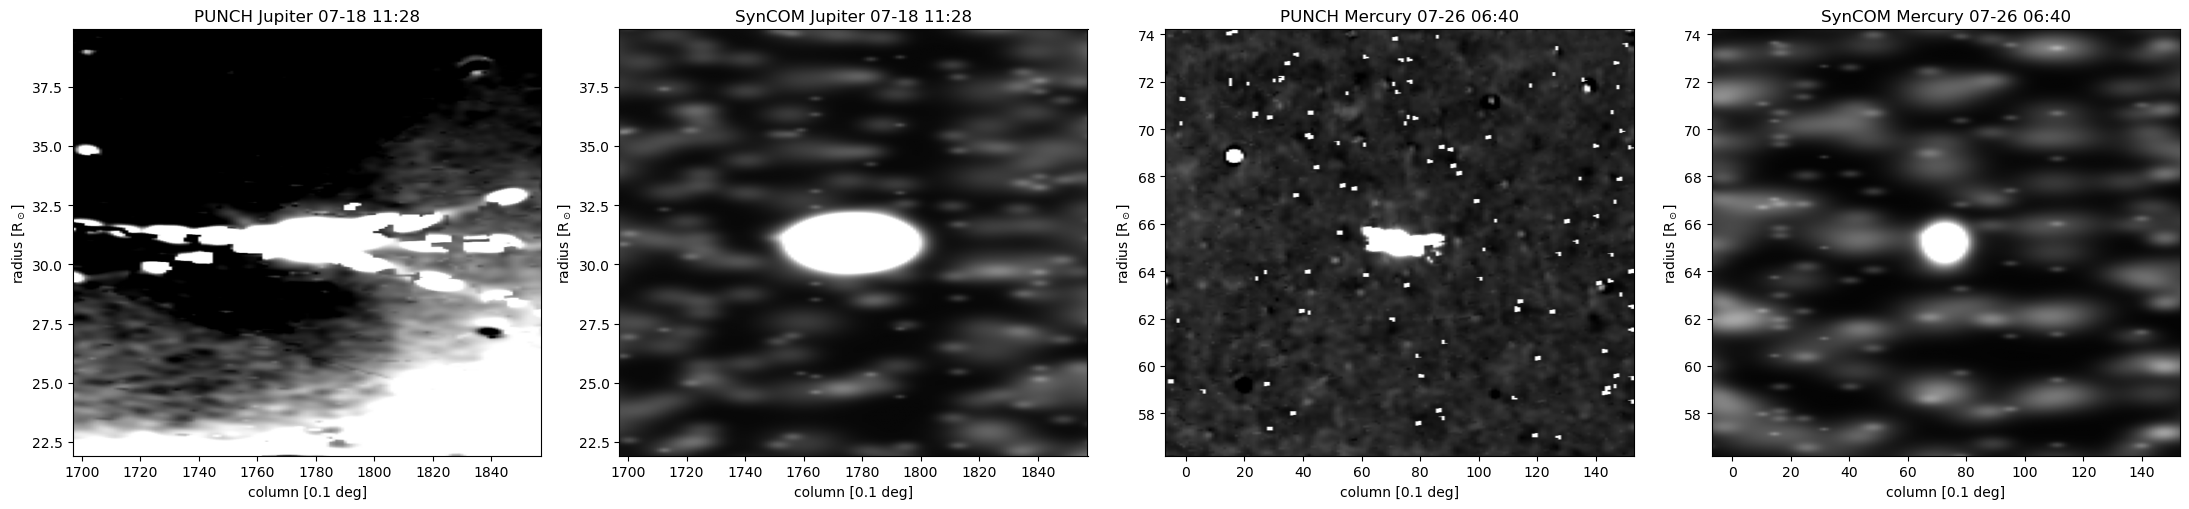

In [7]:
# Side by side, (I - median) / local sigma: Jupiter at 07-18 11:28 (where PUNCH shows it) and Mercury at 07-26 06:40
p18 = planet_params(("jupiter",), "2026-07-18T11:28:00")
tj = syncom_planet_table(p18, 0, 1)["jupiter"]
c18 = syncom_core(1000, 0, 1, syncom_version="test", scale_factor=1.0, simple=True, params=p18)
c18_off = syncom_core(1000, 0, 1, syncom_version="test", scale_factor=1.0, simple=True, params=planet_params((), "2026-07-18T11:28:00"))

def zoom(ax, img, sig, tr, title, hc=80, hr=400):
    c, r = int(round(tr["col"][0])), int(round(tr["r_px"][0]))
    z = img[np.ix_(np.arange(c - hc, c + hc + 1) % 3600, np.arange(r - hr, r + hr + 1))]
    ax.imshow(((z - np.nanmedian(z)) / sig).T, origin="lower", aspect="auto", cmap="gray", vmin=-5, vmax=30,
              extent=[c - hc, c + hc, 5 + (r - hr) * 0.0225, 5 + (r + hr) * 0.0225])
    ax.set(title=title, xlabel="column [0.1 deg]", ylabel=r"radius [R$_\odot$]")

tm = tab["mercury"]
fig, ax = plt.subplots(1, 4, figsize=(22, 5.2))
for k, (fpath, tr, img, img_off, lab) in enumerate(((F18, tj, None, c18_off, "Jupiter 07-18 11:28"), (None, tj, c18, c18_off, "Jupiter 07-18 11:28"),
                                                     (F26, tm, None, c_off, "Mercury 07-26 06:40"), (None, tm, c_both, c_off, "Mercury 07-26 06:40"))):
    rows = np.arange(int(round(tr["r_px"][0])) - 400, int(round(tr["r_px"][0])) + 401)
    if fpath:
        pol, _ = unwrap_punch_polar(fpath, p_pl, rows=rows)
        full = np.full((3600, 7779), np.nan); full[:, rows] = pol
        zoom(ax[k], full, local_sigma(pol, np.arange(380, 421)), tr, "PUNCH " + lab)
    else:
        zoom(ax[k], img[:, :, 0], local_sigma(img_off[:, :, 0], planet_rows({"x": tr}, 7779)), tr, "SynCOM " + lab)
plt.tight_layout(); plt.show()

### 9e. The planet database
`PLANET_DB` lists every planet, its V magnitude formula and whether it was checked against PUNCH. The cell prints each planet's magnitude at opposition (or greatest elongation) in 2026–27, to compare with known values. It then shows that a planet outside the frame for the whole run is not modelled: on 2026-07-26, Saturn is 109° from the Sun.

In [8]:
tt = Time("2026-01-01") + TimeDelta(np.arange(0, 730, 1.0), format="jd")
known = {"mercury": "~ -2.4", "venus": "-4.9", "mars": "-1.2 to -1.3", "jupiter": "-2.7",
         "saturn": "+0.1 to +0.6", "uranus": "+5.6", "neptune": "+7.7"}
print("planet    PUNCH       brightest in 2026-27   known (2026-27)  evidence")
for name, entry in PLANET_DB.items():
    e = planet_ephemeris(name, tt)
    k = np.argmin(e["vmag"])
    print(f"{name:8s}  {entry['punch']:10s}  {e['vmag'][k]:+.2f} ({tt[k].iso[:10]})   {known[name]:18s} {entry['evidence']}")
assert abs(planet_ephemeris("jupiter", Time("2026-01-10"))["vmag"][0] + 2.68) < 0.1
assert abs(planet_ephemeris("uranus", Time("2026-11-26"))["vmag"][0] - 5.60) < 0.1
assert abs(planet_ephemeris("neptune", Time("2026-09-26"))["vmag"][0] - 7.68) < 0.1

print()
assert syncom_planet_table(planet_params(("saturn",)), 0, 10) is None          # outside the frame: not modelled
tab_sm = syncom_planet_table(planet_params(("mercury", "saturn")), 0, 10)
print("planets modelled with PLANETS = ('mercury', 'saturn') on 2026-07-26:", list(tab_sm))
assert list(tab_sm) == ["mercury"]

planet    PUNCH       brightest in 2026-27   known (2026-27)  evidence
mercury   confirmed   -2.44 (2026-05-15)   ~ -2.4             2026-07-18 11:28 (36 Rsun, linear: zero point) and 2026-07-26 06:40 (65 Rsun, saturated)
venus     confirmed   -4.89 (2026-11-25)   -4.9               2026-07-18 11:28 (167 Rsun) and 2026-07-26 06:40 (170 Rsun), saturated


mars      confirmed   -1.28 (2027-02-20)   -1.2 to -1.3       2026-07-18 11:28 (160 Rsun) and 2026-07-26 06:40 (168 Rsun), at the ceiling / linear
jupiter   confirmed   -2.68 (2026-01-09)   -2.7               2026-07-18 11:28 (31 Rsun), saturated; 2026-07-26 inside the area without data
saturn    ephemeris   +0.09 (2027-10-18)   +0.1 to +0.6       outside the PUNCH field in the calibration frames (elongation 101-109 deg)


uranus    ephemeris   +5.58 (2027-11-30)   +5.6               outside the PUNCH field in the calibration frames (elongation 51-59 deg)
neptune   ephemeris   +7.68 (2027-09-28)   +7.7               outside the PUNCH field in the calibration frames (elongation 112-119 deg)

No file or date entered. Using default: syncom_20140414_densfix.sav
  Saturn: r 413.8-413.9 Rsun, outside the frame (5-180 Rsun) for the whole run: not modelled
No file or date entered. Using default: syncom_20140414_densfix.sav
  Saturn: r 413.8-413.9 Rsun, outside the frame (5-180 Rsun) for the whole run: not modelled
planets modelled with PLANETS = ('mercury', 'saturn') on 2026-07-26: ['mercury']


### 9f. The four confirmed planets in one frame (2026-07-18 11:28)
On 2026-07-18 11:28 all four confirmed planets are in the PUNCH field at once. One SynCOM frame of the main notebook's run with `SYNCOM_PLANETS=("mercury", "venus", "mars", "jupiter")` is compared with the PUNCH frame of that time:
- each planet's position (on the sky, in PUNCH pixels);
- its S/N and visible size (30σ diameter);
- the whole frame next to the `movie_generic` PNG, and each planet up close.

No file or date entered. Using default: syncom_20140414_densfix.sav
  Mercury: r 36.43 -> 36.43 Rsun, PA 245.19 -> 245.19 deg, dr/dt 0.000 px/frame (0.0 km/s), V +3.83, S/N 541, in view 1/1 frames
  Venus: r 167.00 -> 167.00 Rsun, PA 94.17 -> 94.17 deg, dr/dt 0.000 px/frame (0.0 km/s), V -4.18, S/N 5699 (saturated), in view 1/1 frames
  Mars: r 160.39 -> 160.39 Rsun, PA 275.46 -> 275.46 deg, dr/dt 0.000 px/frame (0.0 km/s), V +1.31, S/N 5480 (saturated), in view 1/1 frames
  Jupiter: r 30.91 -> 30.91 Rsun, PA 92.33 -> 92.33 deg, dr/dt 0.000 px/frame (0.0 km/s), V -1.79, S/N 2182 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.266697883605957 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 3.97471022605896 seconds


planet    r [Rsun]  PA     V      position: PUNCH - SynCOM   S/N PUNCH  SynCOM  ratio   30-sigma diameter PUNCH  SynCOM  ratio


mercury    36.4   245.2 +3.83    0.8 PUNCH px                    547     535  0.98        0.193   0.185   0.96


venus     167.0    94.2 -4.18    1.3 PUNCH px                   5677    5699  1.00        1.061   0.840   0.79


... (2 outputs left out)

  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.0345070362091064 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  Venus: r 167.00 -> 167.00 Rsun, PA 94.17 -> 94.17 deg, dr/dt 0.000 px/frame (0.0 km/s), V -4.18, S/N 5699 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.08387303352356 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  Mars: r 160.39 -> 160.39 Rsun, PA 275.46 -> 275.46 deg, dr/dt 0.000 px/frame (0.0 km/s), V +1.31, S/N 5480 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.199753999710083 seconds
No file or date entered. Using default: syncom_20140414_densfix.sav
  Jupiter: r 30.91 -> 30.91 Rsun, PA 92.33 -> 92.33 deg, dr/dt 0.000 px/frame (0.0 km/s), V -1.79, S/N 2182 (saturated), in view 1/1 frames
  0% (0/1 frames)


  25% (1/1 frames, 4 s)
  50% (1/1 frames, 4 s)
  75% (1/1 frames, 4 s)
  done (1 frames, 4 s)
⏱️ Total runtime: 4.191855192184448 seconds
four planets together = sum of each planet alone


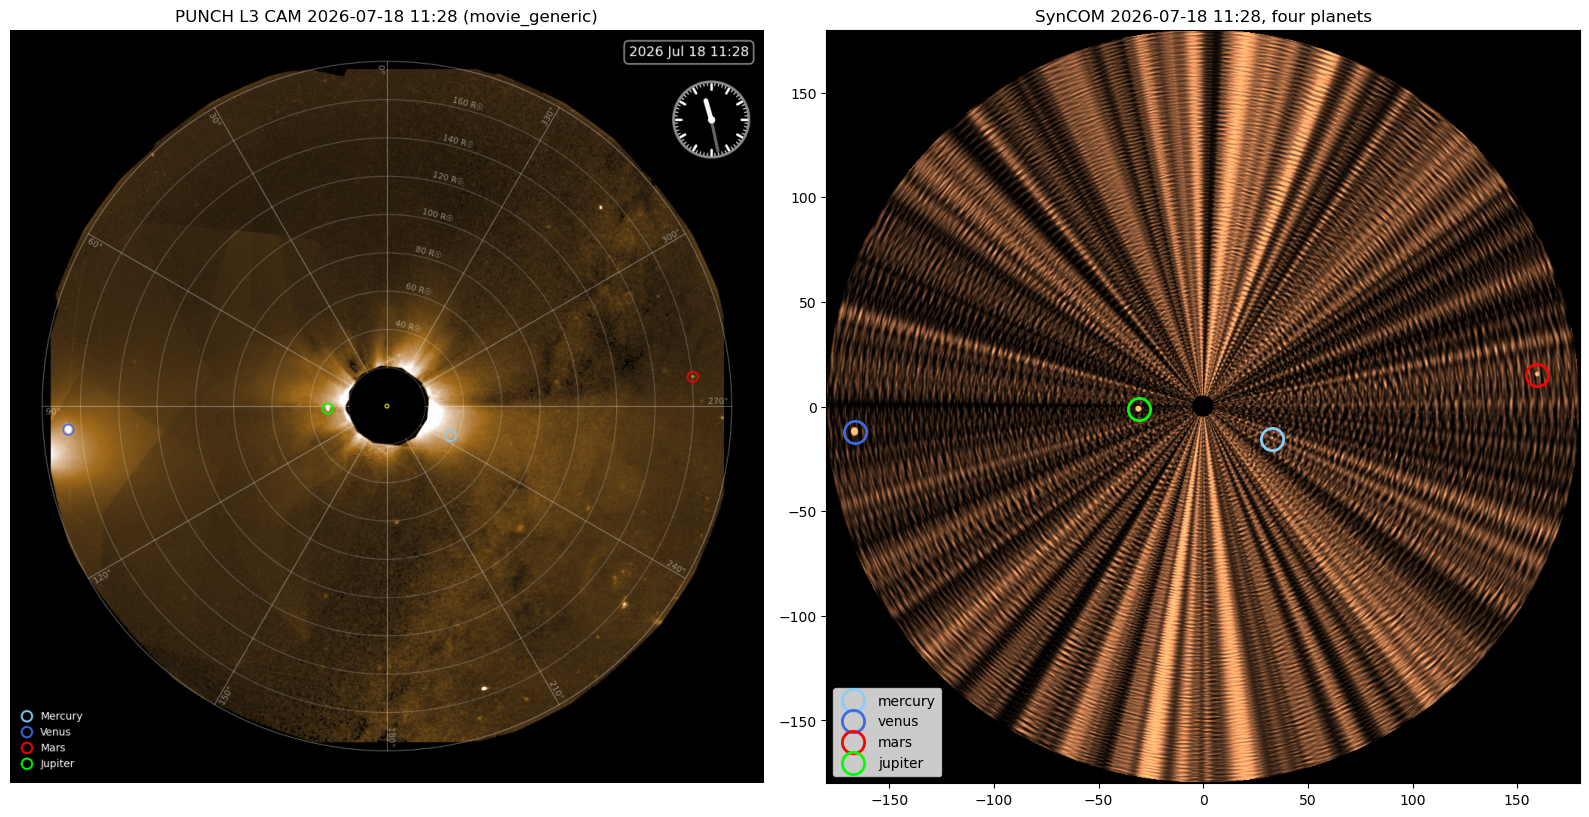

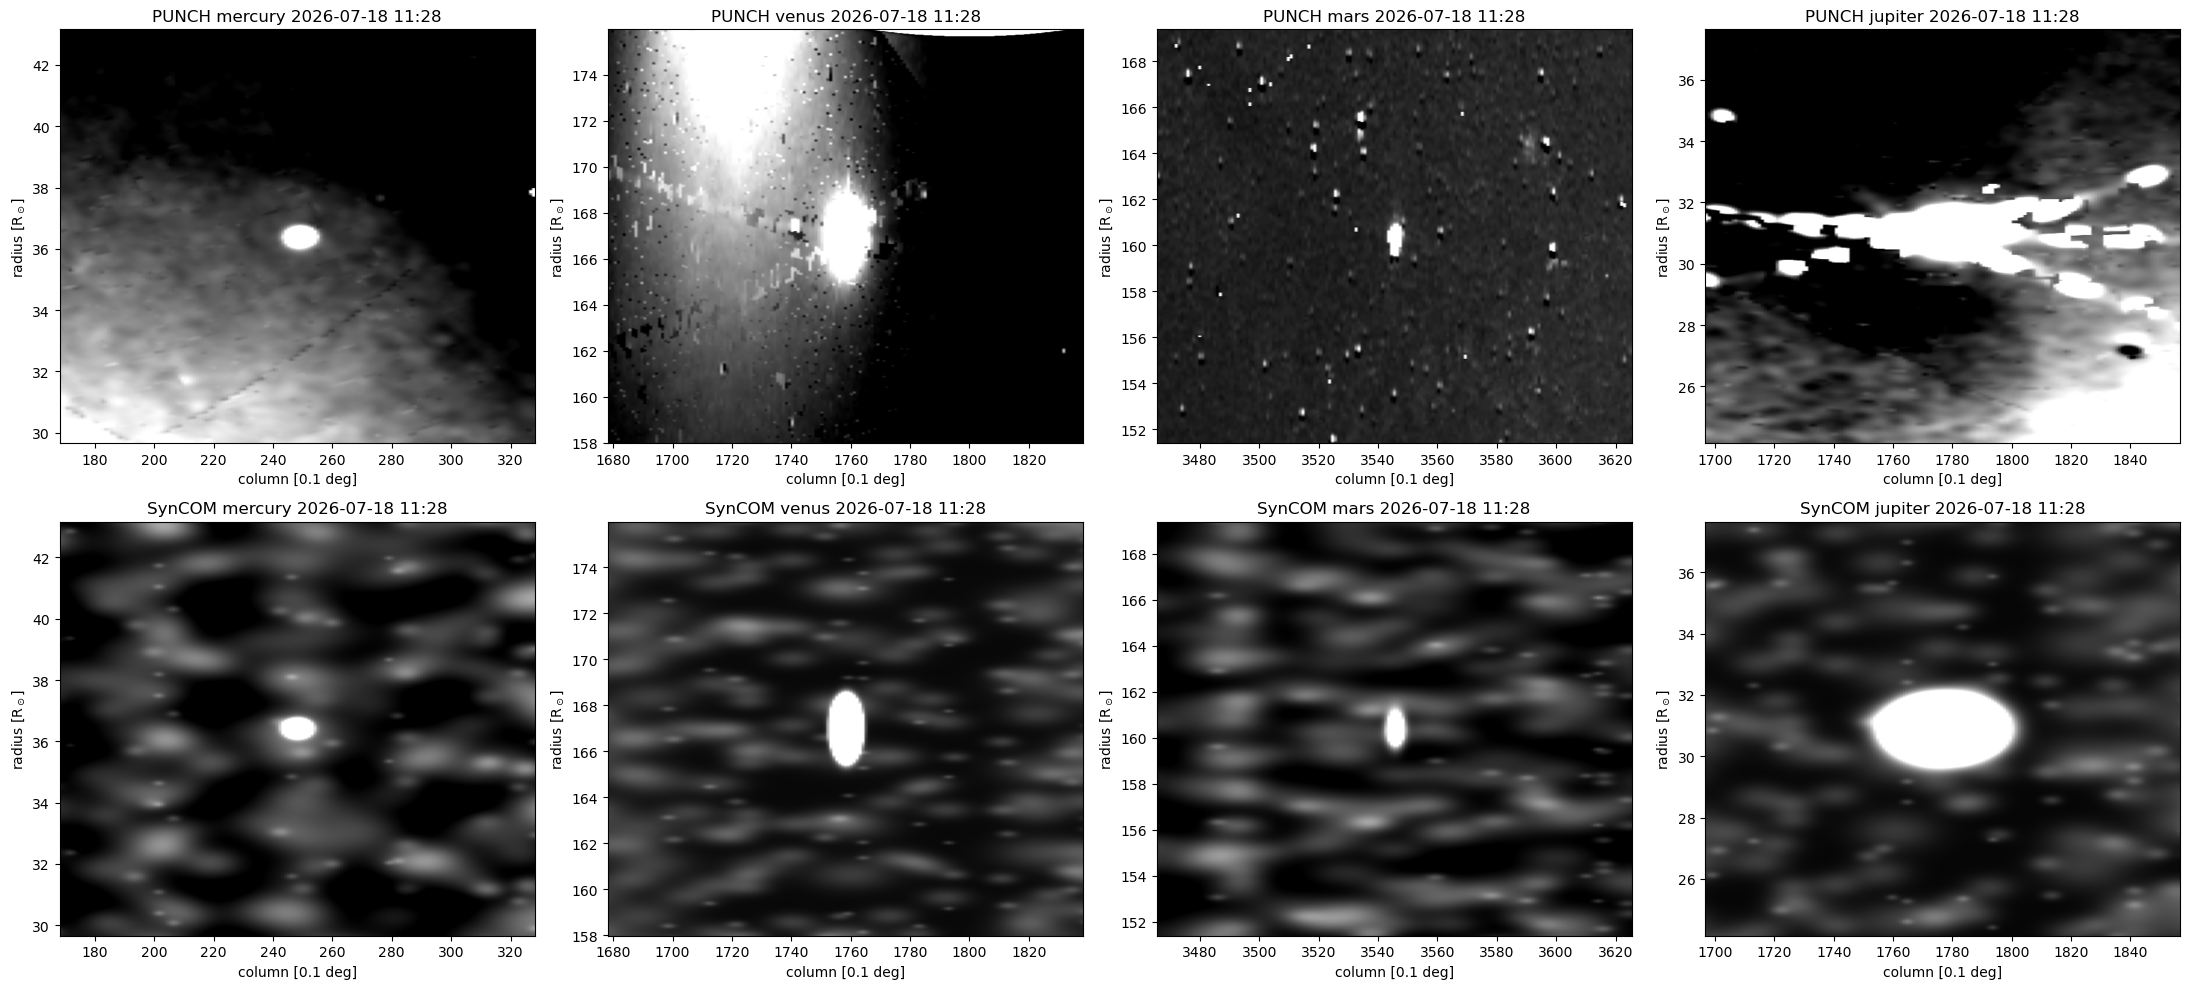

In [9]:
FOUR = ("mercury", "venus", "mars", "jupiter")
p4 = planet_params(FOUR, "2026-07-18T11:28:00")
tab4 = syncom_planet_table(p4, 0, 1)
c4 = syncom_core(1000, 0, 1, scale_factor=1.0, simple=True, params=p4)[:, :, 0]
c4_off = syncom_core(1000, 0, 1, scale_factor=1.0, simple=True, params=planet_params((), "2026-07-18T11:28:00"))[:, :, 0]
sig4 = planet_sigmas(c4_off, tab4)
m4 = c4 - c4_off
from syncom_planets import _source_peak
print("planet    r [Rsun]  PA     V      position: PUNCH - SynCOM   S/N PUNCH  SynCOM  ratio   30-sigma diameter PUNCH  SynCOM  ratio")
for name in FOUR:
    tr = tab4[name]; c0, r0 = tr["col"][0], tr["r_px"][0]
    rows = np.arange(int(r0) - 60, int(r0) + 61)
    pol, _ = unwrap_punch_polar(F18, p4, rows=rows)
    cols = np.arange(int(c0) - 15, int(c0) + 16)
    z = pol[cols % 3600]; z = np.where(np.isfinite(z), z - np.nanmedian(z), 0); w = z * (z > 0.5 * z.max())
    pc, prow = (w.sum(1) @ cols) / w.sum(), (w.sum(0) @ rows) / w.sum()
    sc, sr, pk = moment_centroid(m4, c0, r0)
    loc = planet_pixel_punch(hd18, name)
    sig_p = local_sigma(pol, np.arange(40, 81))
    snr_p, snr_s = _source_peak(d18, loc["x"], loc["y"]) / sig_p, pk / sig4[name]
    d30_p, d30_s = _punch_sizes(d18, loc["x"], loc["y"], sig_p)[1], syncom_size(m4, tr, sig4[name])[1]
    dr = (prow - sr) * 0.0225 * tr["eps"][0] / tr["r"][0]
    dc = (pc - sc) * 0.1 * np.sin(np.radians(tr["eps"][0]))
    dpos = np.hypot(dr, dc) / 0.0225
    print(f"{name:8s} {tr['r'][0]:6.1f}  {tr['pa'][0]:6.1f} {tr['vmag'][0]:+.2f}   {dpos:4.1f} PUNCH px                 "
          f"{snr_p:6.0f}  {snr_s:6.0f}  {snr_s / snr_p:.2f}        {d30_p:.3f}   {d30_s:.3f}   {d30_s / d30_p:.2f}")
    assert dpos <= 2.5 and 0.75 < snr_s / snr_p < 1.33 and 0.75 < d30_s / d30_p < 1.33
alone = sum(syncom_core(1000, 0, 1, scale_factor=1.0, simple=True, params=planet_params((n,), "2026-07-18T11:28:00"))[:, :, 0] - c4_off
            for n in FOUR)
assert np.allclose(alone, m4, atol=1e-9)
print("four planets together = sum of each planet alone")

from syncom_prams import polar_rho_range
R = polar_rho_range(p4)[1]
rect = polar_to_rect(c4, rho_range=polar_rho_range(p4), n=1024)
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(png); ax[0].axis("off"); ax[0].set_title("PUNCH L3 CAM 2026-07-18 11:28 (movie_generic)")
ax[1].imshow(np.where(rect == 0, np.nan, rect).T, origin="lower", extent=[-R, R, -R, R], cmap="copper",
             vmin=np.percentile(c4_off[::4, ::4], 1), vmax=np.percentile(c4_off[::4, ::4], 99.5))
for name in FOUR:
    tr = tab4[name]; ph = np.radians(270 - tr["pa"][0])
    ax[1].plot(tr["r"][0] * np.cos(ph), -tr["r"][0] * np.sin(ph), "o", mfc="none", mec=COLORS[name], ms=16, mew=2, label=name)
ax[1].set_facecolor("black"); ax[1].legend(loc="lower left"); ax[1].set_title("SynCOM 2026-07-18 11:28, four planets")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(22, 10))
for k, name in enumerate(FOUR):
    tr = tab4[name]; c0, r0 = tr["col"][0], tr["r_px"][0]
    hr = 300 if name in ("mercury", "jupiter") else 400
    rows = np.arange(max(int(r0) - hr, 0), min(int(r0) + hr + 1, 7779)); cs = np.arange(int(c0) - 80, int(c0) + 81) % 3600
    pol, _ = unwrap_punch_polar(F18, p4, rows=rows)
    ext = [c0 - 80, c0 + 80, 5 + rows[0] * 0.0225, 5 + rows[-1] * 0.0225]
    for j, (img, sg, who) in enumerate(((pol[cs], local_sigma(pol, np.arange(hr - 20, hr + 21)), "PUNCH"),
                                        (c4[np.ix_(cs, rows)], sig4[name], "SynCOM"))):
        ax[j, k].imshow(((img - np.nanmedian(img)) / sg).T, origin="lower", aspect="auto", cmap="gray", vmin=-5, vmax=30, extent=ext)
        ax[j, k].set(title=f"{who} {name} 2026-07-18 11:28", xlabel="column [0.1 deg]", ylabel=r"radius [R$_\odot$]")
plt.tight_layout(); plt.show()

**Observed.**
- **9a. Locating the planets.** The four PNG markers land on the planets in the FITS data, 0.47–0.91 PNG px away (1 PNG px = 4.6 FITS px). In both files the half-maximum centroids are 0.05–2.1 FITS px from the `movie_generic` ephemeris positions; the largest offsets are the saturated, bleeding planets. On 2026-07-26 Jupiter (9.2 R☉) is in the area of the CAM mosaic without data.
- **9b. Calibration.**
  - **Zero point:** the unsaturated Mercury of 07-18 (V = 3.83). It predicts the Mars peak of 07-18 (V = 1.31) to 1 %.
  - **Saturation:** Jupiter 07-18, Mercury 07-26 and Venus 07-18 / 07-26 are 3.8–150× below their linear peak. Their S/N is the ceiling: 2182 at 31 R☉, 2331 at 65 R☉, 5700–5761 at 167–171 R☉.
  - **Core growth:** fitted to the sizes, 0.28 % per R☉ beyond 36 R☉.
  - **Model vs data, all seven sightings:** S/N 0.83–1.23 of PUNCH; visible (30σ) diameter 0.79–1.15.
  - **Half-maximum (flat-top) diameter:** 0.80–1.98. It is too wide for Venus (×1.5–2) and Mercury 07-26 (×1.36): PUNCH's flat tops are narrower than a clipped profile.
  - **Before this change** a fixed saturated shape made Venus and Jupiter 2–3× too small (30σ diameter 0.41–0.49 of PUNCH).
- **9c. Venus and Mars.** At the times of both frames they are on the PUNCH position (≤ 0.6 columns and ≤ 5.6 rows, within 2.5 PUNCH px). S/N 0.83–1.02 of PUNCH; visible diameter 0.79–1.15.
- **9d. Mercury + Jupiter (2026-07-26 06:40).** Centres on the table to ≤ 0.06 px. S/N exactly the table (2332, 2182; both saturated, so the peak is the ceiling). Speeds +0.391 and −0.423 px/frame, as the ephemeris says. Both together = blobs + each alone; off switch bit-identical.
- **9e. Database.** The magnitudes from the ephemeris match the known values: Jupiter −2.68, Mars −1.28, Venus −4.89, Uranus +5.58, Neptune +7.68; Saturn +0.09 to +1.06 with the ring tilt. Saturn, 109° from the Sun on 2026-07-26, is not modelled: with `("mercury", "saturn")` only Mercury is drawn.
- **9f. Four planets in one frame (2026-07-18 11:28).** Every planet is where PUNCH shows it, within 0.8–2.4 PUNCH px, with S/N 0.83–1.00 and visible diameter 0.79–1.15 of PUNCH. In the Cartesian frame they sit where the `movie_generic` PNG marks them. The four together = the sum of each alone.
- **Not modelled:** the bleed streaks and diffraction spikes of saturated planets (long for Jupiter and Venus), and stars. ✅

## 10. Summary

| check | result |
|---|---|
| `gaussian_profile` shape and 0°/360° wrap-around | ✅ |
| v2 runs out (3 of 14000 copies left at frame 299); v3 is full **from frame 0** (8435–8534 launches at every frame, 1.2% spread) | ✅ |
| a blob begins from its centre, launched $12L$ below 5 R☉ (1.3–4.7 R☉), hidden at launch, crossing 5 R☉ with value 1.000 | ✅ |
| mean brightness equal at every radius (1.000 at 5 R☉, 0.999 at the top); launching at 5 R☉ would give 0.503 | ✅ |
| one blob with $P$ = 1 h crosses 5 R☉ at frames 6, 18, …, 294, launches $vP$ = 120 px apart, field already full at $t = 0$ | ✅ |
| periodicity in the cube: autocorrelation peak at $P$ (exact for one blob, 33 vs 33.10 frames in the sparse run) | ✅ |
| full run: time-delay speed matches the input to 0.0% (fast) and 0.2% (slow) | ✅ |
| frequencies: the Fourier power spectrum recovers each dominant blob's `syncom_load` period to 0.001 frames; the full-run spectrum matches the `syncom_load` prediction (correlation 0.9935, best period scale 1.000) | ✅ |
| 10000 blobs at scale 1, 500 frames: 2.4× more overlap (one period per angle at 31% of angles), but the period population matches `syncom_load` even better (power within 0.7%, best scale 1.005) | ✅ |
| period range measured blind (from the light curves only): within 2.5% of the `syncom_load` 1.5–3 h in all three runs (0.2–0.7% with 500 frames) | ✅ |
| 2000 blobs at scale 1, 500 frames: half the overlap of scale 2 ($N_\text{eff} \propto N \cdot$ scale); one period per angle at 50% of angles; period population matches `syncom_load` (correlation 0.9956, best scale 1.000) | ✅ |
| 30-frame FITS sample of the main notebook's run (10000 blobs): float64, correct headers, bit-identical to the model | ✅ |
| planets (v4-planet_body): PNG markers, FITS data and ephemeris agree (< 1 PNG px, ≤ 2.1 FITS px); brightness from the ephemeris magnitude, linear up to the PUNCH saturation ceiling and clipped there; all 7 planet sightings: S/N 0.83–1.23, visible size 0.79–1.15 of PUNCH; the 4 confirmed planets in one SynCOM frame at 2026-07-18 within 2.4 PUNCH px of PUNCH; any combination of planets; off switch bit-identical | ✅ |

**Conclusion.** In v3-periodic_blobs every blob reappears each time its period is up, before and during the whole simulation. Each blob is launched behind the occulter and slides into the field fully formed. The field is in steady state from the first frame, and its mean brightness is the same at every radius. The speeds and the frequencies in the cube are the ones put in by `syncom_load`, so the synthetic data can be used to validate speed- and period-measuring methods.

**Things to keep in mind**
- **Field of view:** 5–14.335 R☉. `POLAR_RHO_RANGE` is computed from `SYNCOM_PIXEL` in `syncom_prams.py`, so the plots and the simulation always use the same pixel size.
- **Overlap:** with 2000 blobs at scale 2, 50–80 blobs overlap at every position angle. Periods can be read one per position angle only where a blob dominates. Use fewer or smaller blobs if a test needs that.
- **Runtime:** the main run takes ≈3 min for 2000 blobs × 300 frames. Computing the frames takes ≈30 s; most of the rest is saving the float64 `.npz` cube.
